In [192]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import shap
import copy
import warnings
from typing import Optional, Sequence, Any

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, BayesianRidge
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold, cross_val_predict, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from sklearn.neural_network import MLPRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel
from sklearn.experimental import enable_iterative_imputer  # noqa: F401"
from sklearn.impute import SimpleImputer, IterativeImputer

from xgboost import XGBRegressor

from scipy.stats import spearmanr
from scipy.optimize import minimize, minimize_scalar


In [2]:
from scripts.general_model import GlobalResidualRegressor

## Data Setup

In [ ]:
# target variables: 'proctor_mdd_g_cm3', 'proctor_owc_pct'
df = pd.read_csv('../data/train.csv')

df['clay'] = df['psd_passing_at_0_002mm_pct']
df['silt'] = df['psd_passing_at_0_063mm_pct'] - df['psd_passing_at_0_002mm_pct']
df['sand'] = df['psd_passing_at_2mm_pct'] - df['psd_passing_at_0_063mm_pct']
df['gravel'] = 100 - df['psd_passing_at_2mm_pct']
df['fine-grained'] = (df['clay'] + df['silt'] > 15)

# Geotechnical gradation indices
df['feat_cu'] = df['psd_size_at_d60_mm'].replace(0, np.nan) / df['psd_size_at_d10_mm'].replace(0, np.nan) # Coefficient of uniformity
df['feat_cc'] = (df['psd_size_at_d30_mm'] ** 2) / (df['psd_size_at_d60_mm'].replace(0, np.nan) * df['psd_size_at_d10_mm'].replace(0, np.nan)) # Coefficient of curvature
df['feat_log_cu'] = np.log1p(df['feat_cu']) # Log-CU (skewed distribution)
df['feat_pi'] = df['atterberg_liquid_limit_pct'] - df['atterberg_plastic_limit_pct'] # Plasticity Index


features = df.columns.drop(['id'])
inputs = df.columns.drop(['id', 'proctor_mdd_g_cm3', 'proctor_owc_pct'])
outputs = ['proctor_mdd_g_cm3', 'proctor_owc_pct']

dff = df[df['fine-grained']].drop(columns=['fine-grained'])    # fine-grianed
dfc = df[~df['fine-grained']].drop(columns=['fine-grained'])   # coarse-grained

## Global Helpers

In [4]:
def corr_heatmap(input_df, method='pearson', ax=None):
    return sns.heatmap(
            input_df.corr(method=method),
            cmap="coolwarm",
            annot=True,
            fmt=".2f",
            vmin=-1,
            vmax=1,
            square=True,
            ax=ax
    )

## Correlation

### Pearson Correlation

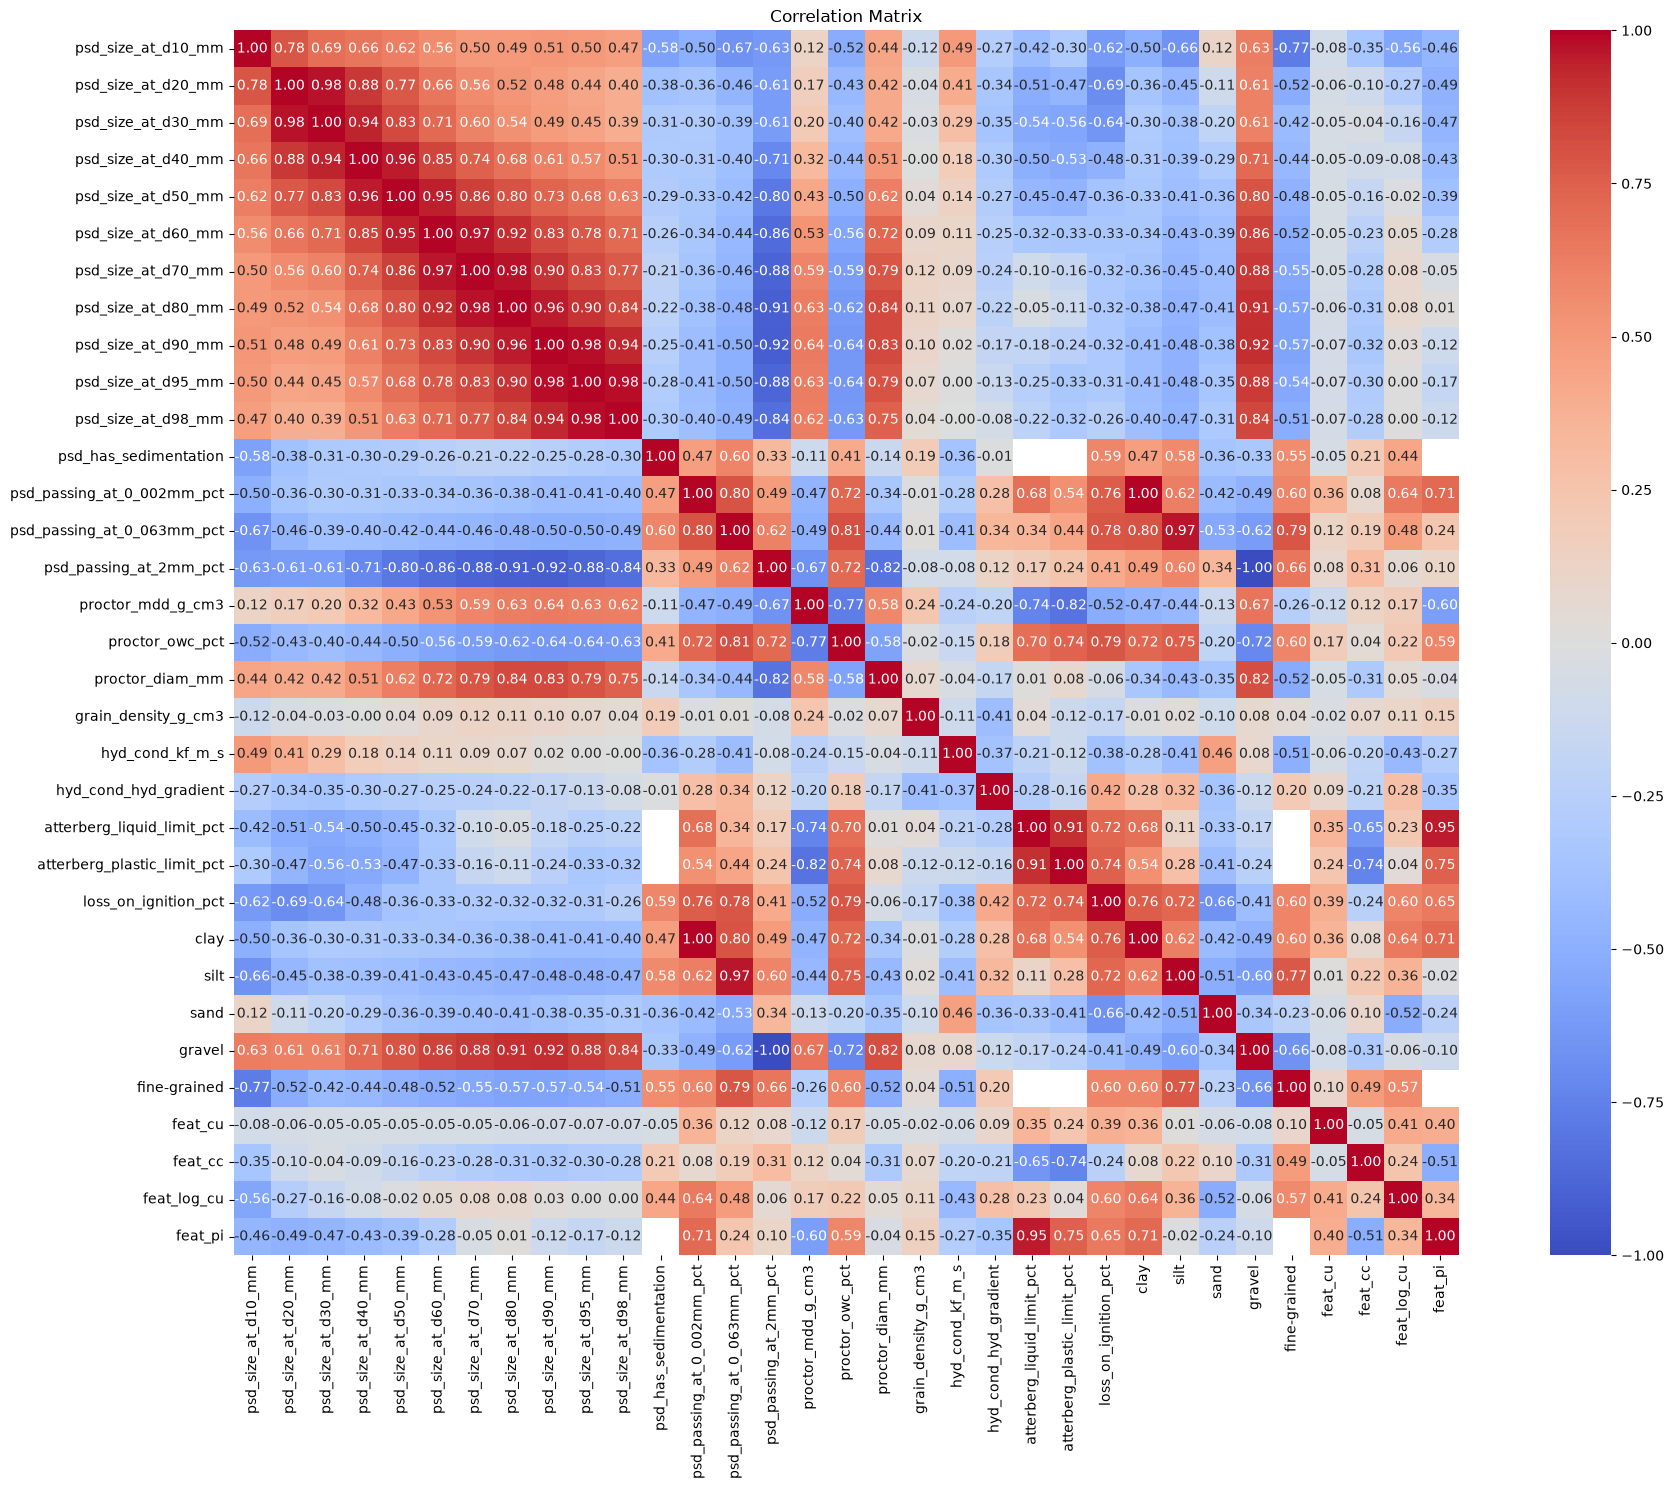

In [5]:
plt.figure(figsize=(20, 15))
corr_heatmap(df[features])

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [6]:
# Checking for correlation value greater than 0.6

temp = ['psd_has_sedimentation', 'psd_passing_at_0_002mm_pct', 'psd_passing_at_0_063mm_pct',
       'psd_passing_at_2mm_pct', 'proctor_diam_mm', 'grain_density_g_cm3', 'hyd_cond_kf_m_s',
       'hyd_cond_hyd_gradient', 'atterberg_liquid_limit_pct', 'atterberg_plastic_limit_pct', 'loss_on_ignition_pct']

lst = []

for col in df[temp]:
    for row in df[temp]:
        if row == col:  # want upper trianglar
            break
        elif abs(df[inputs].corr().round(5).loc[row, col]) >= 0.9:
            lst.append([row, col])

# len(lst)
lst

[['atterberg_liquid_limit_pct', 'atterberg_plastic_limit_pct']]

In [7]:
# Pearson Correlation - how strongly two variables have a linear relationship

# Features and targets
X = df[inputs]
y_mdd = df["proctor_mdd_g_cm3"]
y_owc = df["proctor_owc_pct"]

# Compute correlations
pearson_mdd = X.corrwith(y_mdd, method="pearson")
pearson_owc = X.corrwith(y_owc, method="pearson")

# Combine into one DataFrame
pearson_df = pd.DataFrame({
    "MDD_pearson": pearson_mdd,
    "OWC_pearson": pearson_owc
})

### Spearman Correlation

In [8]:
# Features and targets
X = df[inputs]
y_mdd = df["proctor_mdd_g_cm3"]
y_owc = df["proctor_owc_pct"]

# Compute correlations
spearman_mdd = X.corrwith(y_mdd, method="spearman")
spearman_owc = X.corrwith(y_owc, method="spearman")

# Combine into one DataFrame
spearman_df = pd.DataFrame({
    "MDD_spearman": spearman_mdd,
    "OWC_spearman": spearman_owc
})

### Pairwise Correlation

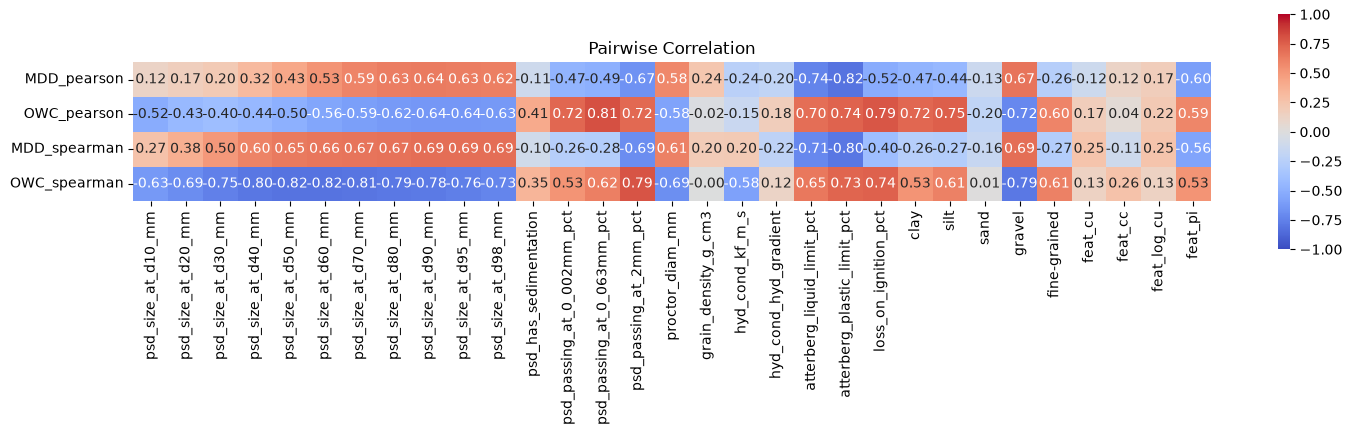

In [9]:
corr_pairwise_mat = pd.concat([pearson_df, spearman_df], axis=1)

plt.figure(figsize=(15,4))

sns.heatmap(
    corr_pairwise_mat.T,
    cmap='coolwarm',
    annot=True,      # Show correlation values
    fmt='.2f',       # 2 decimal places
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Pairwise Correlation")
plt.tight_layout()
plt.show()

### Mutual Information

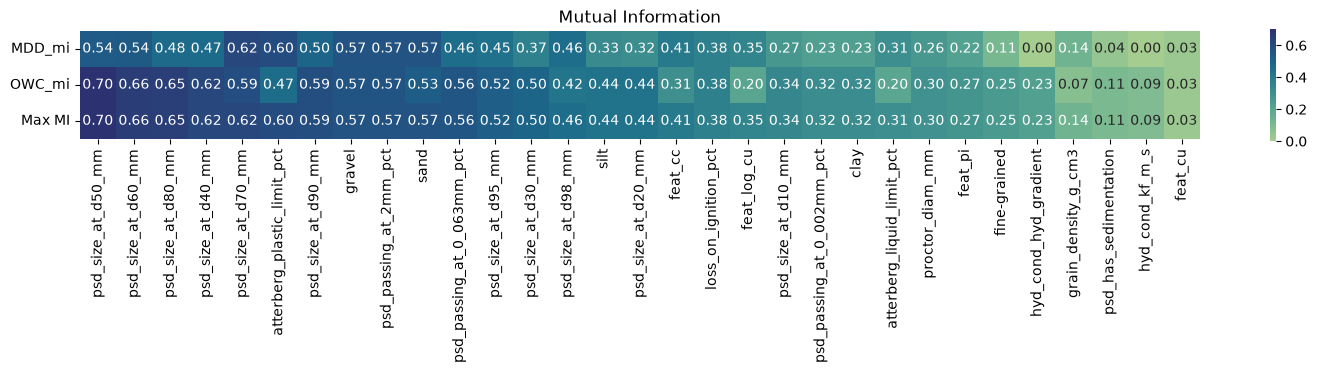

In [10]:
# Mutual Information - how much knowing one variable reduces your uncertainty about another variable

mi_mdd = {}
mi_owc = {}

for feature in X.columns:
    # ----- MDD -----
    temp = pd.concat([X[feature], y_mdd], axis=1).dropna()

    mi_mdd[feature] = mutual_info_regression(
        temp[[feature]],
        temp[y_mdd.name],
        random_state=42
    )[0]

    # ----- OWC -----
    temp = pd.concat([X[feature], y_owc], axis=1).dropna()

    mi_owc[feature] = mutual_info_regression(
        temp[[feature]],
        temp[y_owc.name],
        random_state=42
    )[0]

mi_df = pd.DataFrame({
    "MDD_mi": mi_mdd,
    "OWC_mi": mi_owc
})

mi_df["Max MI"] = mi_df.max(axis=1)
mi_df = mi_df.sort_values("Max MI", ascending=False)

plt.figure(figsize=(15, 3))
sns.heatmap(
    mi_df.T,
    cmap='crest',
    annot=True,      # Show correlation values
    fmt='.2f',       # 2 decimal places
    vmin=0,
    square=True,
)

plt.title("Mutual Information")
plt.tight_layout()
plt.show()

## Linearity

In [11]:
params_av = df.columns.drop(['hyd_cond_kf_m_s', 'hyd_cond_hyd_gradient', 'atterberg_liquid_limit_pct', 
                             'atterberg_plastic_limit_pct', 'loss_on_ignition_pct', 'feat_pi', 'id', 'proctor_mdd_g_cm3', 'proctor_owc_pct'])

df_reg = df.copy()

### Linear Regression

In [12]:
# How much of the problem is linearly explainable
# Which features still matter after accounting for all the others

X = df[params_av]
y1 = df[outputs[0]]   # MDD
y2 = df[outputs[1]]   # OWC

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

model1 = make_pipeline(StandardScaler(), LinearRegression())
model2 = make_pipeline(StandardScaler(), LinearRegression())

cv_mdd = cross_validate(
    model1,
    X,
    y1,
    cv=cv,
    scoring="r2",
    return_train_score=True
)

cv_owc = cross_validate(
    model2,
    X,
    y2,
    cv=cv,
    scoring="r2",
    return_train_score=True
)

cv_results_lin = pd.DataFrame({
    "MDD train R2": cv_mdd["train_score"],
    "MDD validation R2": cv_mdd["test_score"],
    "OWC train R2": cv_owc["train_score"],
    "OWC validation R2": cv_owc["test_score"]
})

cv_results_lin.index = [f"Fold {i}" for i in range(1, len(cv_results_lin) + 1)]

cv_results_lin.loc["Mean"] = cv_results_lin.mean()
cv_results_lin.loc["Std"] = cv_results_lin.std()

cv_results_lin

,MDD train R2,MDD validation R2,OWC train R2,OWC validation R2
Fold 1,0.836696,0.630188,0.853102,0.613692
Fold 2,0.824884,0.674293,0.826146,0.769505
Fold 3,0.812550,0.755529,0.827822,0.764309
Fold 4,0.786667,0.854315,0.807393,-1.450724
Fold 5,0.804525,0.805894,0.818225,0.812402
Mean,0.813064,0.744044,0.826538,0.301837
Std,0.017136,0.082396,0.015120,0.878862


In [13]:
# If this feature increases by one unit, while all other features stay fixed, how much does the predicted target change?

model1.fit(X, y1)
model2.fit(X, y2)

coef1 = pd.Series(model1.named_steps["linearregression"].coef_, index=X.columns)
coef2 = pd.Series(model2.named_steps["linearregression"].coef_, index=X.columns)

a = coef1.sort_values()
b = coef2.sort_values()

pd.concat([a, b], axis=1).rename(columns={0 : 'mdd', 1 : 'owc'})

,mdd,owc
psd_size_at_d60_mm,-0.088817,1.831689
psd_size_at_d90_mm,-0.047083,-0.395053
psd_passing_at_2mm_pct,-0.044179,0.428198
psd_size_at_d30_mm,-0.042143,-2.847412
psd_size_at_d10_mm,-0.036999,-0.874500
psd_passing_at_0_063mm_pct,-0.027203,0.594263
silt,-0.025780,0.463975
psd_size_at_d80_mm,-0.024318,2.053701
psd_passing_at_0_002mm_pct,-0.023015,0.744576
clay,-0.023015,0.744576


In [14]:
mdd_oof_pred = cross_val_predict(model1, X, y1, cv=cv)
owc_oof_pred = cross_val_predict(model2, X, y2, cv=cv)

In [15]:
# Linear Predictions & Residuals
df_reg['mdd_lin_pred'] = mdd_oof_pred
df_reg['owc_lin_pred'] = owc_oof_pred
df_reg['mdd_lin_res'] = df_reg['proctor_mdd_g_cm3'] - df_reg['mdd_lin_pred']
df_reg['owc_lin_res'] = df_reg['proctor_owc_pct'] - df_reg['owc_lin_pred']
df_reg['mdd_lin_res_pct'] = (df_reg['proctor_mdd_g_cm3'] - df_reg['mdd_lin_pred']) / df_reg['proctor_mdd_g_cm3']
df_reg['owc_lin_res_pct'] = (df_reg['proctor_owc_pct'] - df_reg['owc_lin_pred']) / df_reg['proctor_owc_pct']
df_reg

,id,psd_size_at_d10_mm,psd_size_at_d20_mm,psd_size_at_d30_mm,psd_size_at_d40_mm,psd_size_at_d50_mm,psd_size_at_d60_mm,psd_size_at_d70_mm,psd_size_at_d80_mm,psd_size_at_d90_mm,...,feat_cu,feat_cc,feat_log_cu,feat_pi,mdd_lin_pred,owc_lin_pred,mdd_lin_res,owc_lin_res,mdd_lin_res_pct,owc_lin_res_pct
0,0,0.136773,0.315214,0.547515,0.933930,1.788142,3.313938,7.214010,12.517275,20.160863,...,24.229475,0.661374,3.228013,NaN,2.099124,7.316685,-0.031124,0.743315,-0.015050,0.092223
1,1,0.014579,0.062060,0.119258,0.221877,0.423550,1.022249,2.978369,6.081199,10.622063,...,70.117909,0.954313,4.264339,NaN,2.092984,9.721143,-0.055984,0.698857,-0.027484,0.067069
2,2,0.003243,0.022301,0.087024,0.156595,0.217595,0.323793,0.512853,1.546115,10.921905,...,99.843663,7.212132,4.613571,12.70,2.098875,10.242048,-0.047875,0.697952,-0.023342,0.063798
3,3,0.000355,0.000859,0.002080,0.004772,0.009031,0.015228,0.025404,0.041920,0.151357,...,42.895775,0.800305,3.781818,25.19,1.666542,19.638413,-0.018542,0.671587,-0.011251,0.033067
4,4,0.000360,0.004868,0.010546,0.015848,0.021282,0.026753,0.033510,0.042328,0.067946,...,74.313889,11.547834,4.321665,NaN,1.904840,15.605387,-0.084840,0.154613,-0.046616,0.009810
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
196,196,0.100777,0.212256,0.341667,0.526610,0.955715,2.339938,4.493148,7.795487,16.941993,...,23.218969,0.495040,3.187136,NaN,2.088715,7.425472,-0.031715,0.474528,-0.015418,0.060067
197,197,0.090191,0.126268,0.176777,0.247489,0.346487,0.485085,0.679124,0.950781,1.847298,...,5.378419,0.714283,1.852920,NaN,1.892141,10.363236,-0.042141,-2.163236,-0.022779,-0.263809
198,198,0.176777,0.303513,0.407383,0.559104,0.807431,1.353154,3.230437,9.337932,19.882790,...,7.654582,0.693798,2.158089,NaN,1.993975,8.629379,0.065025,0.390621,0.031581,0.043306
199,199,0.000390,0.001069,0.002937,0.007530,0.014572,0.031049,0.105558,0.312777,0.629716,...,79.612821,0.712354,4.389658,NaN,1.741073,17.283858,-0.030073,1.746142,-0.017576,0.091757


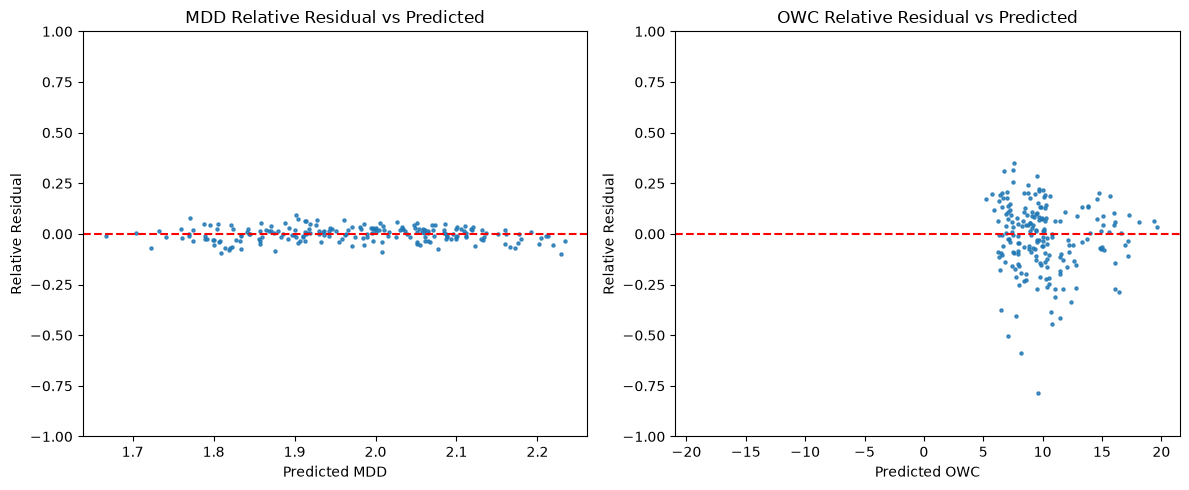

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].set_ylim(-1, 1)
ax[1].set_ylim(-1, 1)

# MDD
ax[0].scatter(
    df_reg['mdd_lin_pred'],
    df_reg['mdd_lin_res_pct'],
    alpha=0.8,
    s=5
)
ax[0].axhline(0, color='red', linestyle='--')
ax[0].set_xlabel("Predicted MDD")
ax[0].set_ylabel("Relative Residual")
ax[0].set_title("MDD Relative Residual vs Predicted")

# OWC
ax[1].scatter(
    df_reg['owc_lin_pred'],
    df_reg['owc_lin_res_pct'],
    alpha=0.8,
    s=5
)
ax[1].axhline(0, color='red', linestyle='--')
ax[1].set_xlabel("Predicted OWC")
ax[1].set_ylabel("Relative Residual")
ax[1].set_title("OWC Relative Residual vs Predicted")

plt.tight_layout()
plt.show()

### Ridge

In [17]:
# Linear Predictions & Residuals with Ridge

alphas = np.logspace(-4, 4, 100)

model3 = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas, cv=5))
model4 = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas, cv=5))

model3.fit(X, y1)
model4.fit(X, y2)

ridge_mdd_oof = cross_val_predict(model3, X, y1, cv=cv)
ridge_owc_oof = cross_val_predict(model4, X, y2, cv=cv)

df_reg['mdd_ridge'] = ridge_mdd_oof
df_reg['owc_ridge'] = ridge_owc_oof
df_reg['mdd_ridge_res'] = df_reg['proctor_mdd_g_cm3'] - df_reg['mdd_ridge']
df_reg['owc_ridge_res'] = df_reg['proctor_owc_pct'] - df_reg['owc_ridge']
df_reg['mdd_ridge_res_pct'] = (df_reg['proctor_mdd_g_cm3'] - df_reg['mdd_ridge']) / df_reg['proctor_mdd_g_cm3']
df_reg['owc_ridge_res_pct'] = (df_reg['proctor_owc_pct'] - df_reg['owc_ridge']) / df_reg['proctor_owc_pct']

print("Best alpha (MDD):", model3.named_steps["ridgecv"].alpha_)
print("Best alpha (OWC):", model4.named_steps["ridgecv"].alpha_)

df_reg

Best alpha (MDD): 17.886495290574352
Best alpha (OWC): 25.950242113997373


,id,psd_size_at_d10_mm,psd_size_at_d20_mm,psd_size_at_d30_mm,psd_size_at_d40_mm,psd_size_at_d50_mm,psd_size_at_d60_mm,psd_size_at_d70_mm,psd_size_at_d80_mm,psd_size_at_d90_mm,...,mdd_lin_res,owc_lin_res,mdd_lin_res_pct,owc_lin_res_pct,mdd_ridge,owc_ridge,mdd_ridge_res,owc_ridge_res,mdd_ridge_res_pct,owc_ridge_res_pct
0,0,0.136773,0.315214,0.547515,0.933930,1.788142,3.313938,7.214010,12.517275,20.160863,...,-0.031124,0.743315,-0.015050,0.092223,2.084984,7.470042,-0.016984,0.589958,-0.008213,0.073196
1,1,0.014579,0.062060,0.119258,0.221877,0.423550,1.022249,2.978369,6.081199,10.622063,...,-0.055984,0.698857,-0.027484,0.067069,2.068569,9.971334,-0.031569,0.448666,-0.015498,0.043058
2,2,0.003243,0.022301,0.087024,0.156595,0.217595,0.323793,0.512853,1.546115,10.921905,...,-0.047875,0.697952,-0.023342,0.063798,2.101041,10.548619,-0.050041,0.391381,-0.024398,0.035775
3,3,0.000355,0.000859,0.002080,0.004772,0.009031,0.015228,0.025404,0.041920,0.151357,...,-0.018542,0.671587,-0.011251,0.033067,1.697727,18.510374,-0.049727,1.799626,-0.030174,0.088608
4,4,0.000360,0.004868,0.010546,0.015848,0.021282,0.026753,0.033510,0.042328,0.067946,...,-0.084840,0.154613,-0.046616,0.009810,1.922732,15.218413,-0.102732,0.541587,-0.056446,0.034365
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
196,196,0.100777,0.212256,0.341667,0.526610,0.955715,2.339938,4.493148,7.795487,16.941993,...,-0.031715,0.474528,-0.015418,0.060067,2.072649,8.122653,-0.015649,-0.222653,-0.007608,-0.028184
197,197,0.090191,0.126268,0.176777,0.247489,0.346487,0.485085,0.679124,0.950781,1.847298,...,-0.042141,-2.163236,-0.022779,-0.263809,1.905806,9.817001,-0.055806,-1.617001,-0.030166,-0.197195
198,198,0.176777,0.303513,0.407383,0.559104,0.807431,1.353154,3.230437,9.337932,19.882790,...,0.065025,0.390621,0.031581,0.043306,2.006228,8.051257,0.052772,0.968743,0.025630,0.107399
199,199,0.000390,0.001069,0.002937,0.007530,0.014572,0.031049,0.105558,0.312777,0.629716,...,-0.030073,1.746142,-0.017576,0.091757,1.757041,16.518788,-0.046041,2.511212,-0.026909,0.131961


In [18]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_mdd = cross_validate(model3, X, y1, cv=cv, scoring="r2", return_train_score=True)

cv_owc = cross_validate(model4, X, y2, cv=cv, scoring="r2", return_train_score=True)

cv_results_ridge = pd.DataFrame({
    "MDD train R2": cv_mdd["train_score"],
    "MDD validation R2": cv_mdd["test_score"],
    "OWC train R2": cv_owc["train_score"],
    "OWC validation R2": cv_owc["test_score"]
})

cv_results_ridge.index = [
    f"Fold {i}"
    for i in range(1, len(cv_results_ridge) + 1)
]

cv_results_ridge.loc["Mean"] = cv_results_ridge.mean()
cv_results_ridge.loc["Std"] = cv_results_ridge.std()

cv_results_ridge

,MDD train R2,MDD validation R2,OWC train R2,OWC validation R2
Fold 1,0.822539,0.687307,0.834178,0.672253
Fold 2,0.808640,0.703571,0.812477,0.758101
Fold 3,0.798284,0.746013,0.817283,0.755092
Fold 4,0.764871,0.755571,0.790596,-1.080161
Fold 5,0.793517,0.784406,0.804007,0.833301
Mean,0.797570,0.735374,0.811708,0.387717
Std,0.019142,0.035347,0.014433,0.735707


### Linear Regression vs. Ridge

In [19]:
cv_results_lin = pd.concat([cv_results_lin.rename(columns={
    'MDD train R2' : 'MDD train R2 (lin)', 
    'MDD validation R2' : 'MDD val R2 (lin)', 
    'OWC train R2' : 'OWC train R2 (lin)', 
    'OWC validation R2' : 'OWC val R2 (lin)', 
}), cv_results_ridge.rename(columns={
    'MDD train R2' : 'MDD train R2 (rid)', 
    'MDD validation R2' : 'MDD val R2 (rid)', 
    'OWC train R2' : 'OWC train R2 (rid)', 
    'OWC validation R2' : 'OWC val R2 (rid)', 
})], axis=1)

cv_results_lin['mdd_win'] = np.where(cv_results_lin['MDD val R2 (lin)'] > cv_results_lin['MDD val R2 (rid)'], 'lin', 'rid')
cv_results_lin['owc_win'] = np.where(cv_results_lin['OWC val R2 (lin)'] > cv_results_lin['OWC val R2 (rid)'], 'lin', 'rid')
# for std, we want to minimize it, so actually, ridge wins for both mdd and owc. 

cv_results_lin 

,MDD train R2 (lin),MDD val R2 (lin),OWC train R2 (lin),OWC val R2 (lin),MDD train R2 (rid),MDD val R2 (rid),OWC train R2 (rid),OWC val R2 (rid),mdd_win,owc_win
Fold 1,0.836696,0.630188,0.853102,0.613692,0.822539,0.687307,0.834178,0.672253,rid,rid
Fold 2,0.824884,0.674293,0.826146,0.769505,0.808640,0.703571,0.812477,0.758101,rid,lin
Fold 3,0.812550,0.755529,0.827822,0.764309,0.798284,0.746013,0.817283,0.755092,lin,lin
Fold 4,0.786667,0.854315,0.807393,-1.450724,0.764871,0.755571,0.790596,-1.080161,lin,rid
Fold 5,0.804525,0.805894,0.818225,0.812402,0.793517,0.784406,0.804007,0.833301,lin,rid
Mean,0.813064,0.744044,0.826538,0.301837,0.797570,0.735374,0.811708,0.387717,lin,rid
Std,0.017136,0.082396,0.015120,0.878862,0.019142,0.035347,0.014433,0.735707,lin,lin


In [20]:
df_reg

,id,psd_size_at_d10_mm,psd_size_at_d20_mm,psd_size_at_d30_mm,psd_size_at_d40_mm,psd_size_at_d50_mm,psd_size_at_d60_mm,psd_size_at_d70_mm,psd_size_at_d80_mm,psd_size_at_d90_mm,...,mdd_lin_res,owc_lin_res,mdd_lin_res_pct,owc_lin_res_pct,mdd_ridge,owc_ridge,mdd_ridge_res,owc_ridge_res,mdd_ridge_res_pct,owc_ridge_res_pct
0,0,0.136773,0.315214,0.547515,0.933930,1.788142,3.313938,7.214010,12.517275,20.160863,...,-0.031124,0.743315,-0.015050,0.092223,2.084984,7.470042,-0.016984,0.589958,-0.008213,0.073196
1,1,0.014579,0.062060,0.119258,0.221877,0.423550,1.022249,2.978369,6.081199,10.622063,...,-0.055984,0.698857,-0.027484,0.067069,2.068569,9.971334,-0.031569,0.448666,-0.015498,0.043058
2,2,0.003243,0.022301,0.087024,0.156595,0.217595,0.323793,0.512853,1.546115,10.921905,...,-0.047875,0.697952,-0.023342,0.063798,2.101041,10.548619,-0.050041,0.391381,-0.024398,0.035775
3,3,0.000355,0.000859,0.002080,0.004772,0.009031,0.015228,0.025404,0.041920,0.151357,...,-0.018542,0.671587,-0.011251,0.033067,1.697727,18.510374,-0.049727,1.799626,-0.030174,0.088608
4,4,0.000360,0.004868,0.010546,0.015848,0.021282,0.026753,0.033510,0.042328,0.067946,...,-0.084840,0.154613,-0.046616,0.009810,1.922732,15.218413,-0.102732,0.541587,-0.056446,0.034365
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
196,196,0.100777,0.212256,0.341667,0.526610,0.955715,2.339938,4.493148,7.795487,16.941993,...,-0.031715,0.474528,-0.015418,0.060067,2.072649,8.122653,-0.015649,-0.222653,-0.007608,-0.028184
197,197,0.090191,0.126268,0.176777,0.247489,0.346487,0.485085,0.679124,0.950781,1.847298,...,-0.042141,-2.163236,-0.022779,-0.263809,1.905806,9.817001,-0.055806,-1.617001,-0.030166,-0.197195
198,198,0.176777,0.303513,0.407383,0.559104,0.807431,1.353154,3.230437,9.337932,19.882790,...,0.065025,0.390621,0.031581,0.043306,2.006228,8.051257,0.052772,0.968743,0.025630,0.107399
199,199,0.000390,0.001069,0.002937,0.007530,0.014572,0.031049,0.105558,0.312777,0.629716,...,-0.030073,1.746142,-0.017576,0.091757,1.757041,16.518788,-0.046041,2.511212,-0.026909,0.131961


### Coefficient Comparison

In [21]:
alphas = np.logspace(-4, 4, 100)
lin = make_pipeline(StandardScaler(), LinearRegression())
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas, cv=5))

lin.fit(X, y1)
ridge.fit(X, y1)

coef_linear = pd.Series(lin.named_steps["linearregression"].coef_, index=params_av)
coef_ridge = pd.Series(ridge.named_steps["ridgecv"].coef_, index=params_av)

coef_compare = pd.DataFrame({
    "Linear": coef_linear,
    "Ridge": coef_ridge
})

coef_compare["Difference"] = (coef_compare["Linear"] - coef_compare["Ridge"])

print(ridge.named_steps["ridgecv"].alpha_)
coef_compare

17.886495290574352


,Linear,Ridge,Difference
psd_size_at_d10_mm,-0.036999,-0.026851,-0.010148
psd_size_at_d20_mm,0.016844,-0.012350,0.029194
psd_size_at_d30_mm,-0.042143,-0.011286,-0.030858
psd_size_at_d40_mm,-0.014161,-0.003123,-0.011038
psd_size_at_d50_mm,0.052228,0.002771,0.049458
psd_size_at_d60_mm,-0.088817,-0.001118,-0.087698
psd_size_at_d70_mm,0.092419,0.006347,0.086072
psd_size_at_d80_mm,-0.024318,0.002192,-0.026510
psd_size_at_d90_mm,-0.047083,-0.003127,-0.043956
psd_size_at_d95_mm,-0.001416,0.001834,-0.003250


## Latent Structure

### PCA

In [22]:
X = df[params_av]

# Remove targets if included
X = X.drop(columns=["proctor_mdd_g_cm3", "proctor_owc_pct"],
           errors="ignore")

X = X.fillna(X.median())

X_scaled = StandardScaler().fit_transform(X)

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

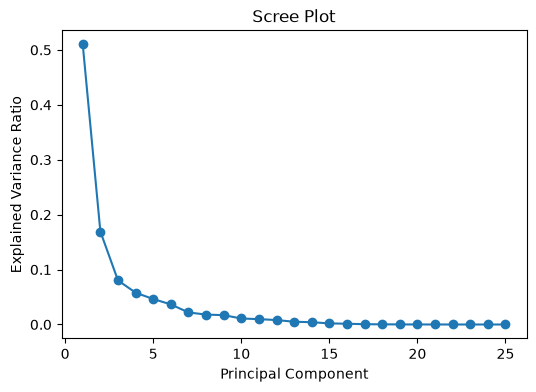

In [23]:
explained_var = pca.explained_variance_ratio_

plt.figure(figsize=(6,4))
plt.plot(range(1, len(explained_var)+1),
         explained_var,
         marker="o")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Scree Plot")
plt.show()

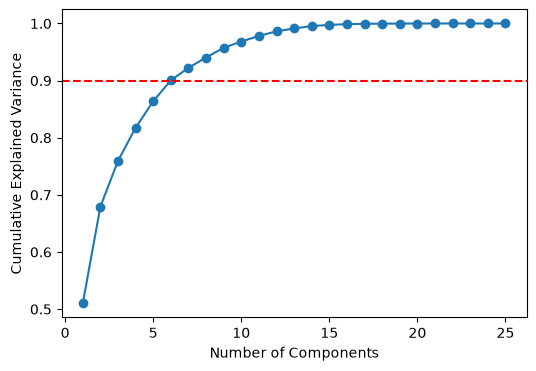

In [24]:
cum_var = np.cumsum(explained_var)

plt.figure(figsize=(6,4))
plt.plot(range(1, len(cum_var)+1),
         cum_var,
         marker="o")
plt.axhline(0.90, color="red", linestyle="--")
# "How many latent dimensions explain 90% of the variation?"

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.show()

In [25]:
loadings = pd.DataFrame(
    pca.components_,
    columns=X.columns,
    index=[f"PC{i+1}" for i in range(len(X.columns))]
)

loadings

,psd_size_at_d10_mm,psd_size_at_d20_mm,psd_size_at_d30_mm,psd_size_at_d40_mm,psd_size_at_d50_mm,psd_size_at_d60_mm,psd_size_at_d70_mm,psd_size_at_d80_mm,psd_size_at_d90_mm,psd_size_at_d95_mm,...,proctor_diam_mm,grain_density_g_cm3,clay,silt,sand,gravel,fine-grained,feat_cu,feat_cc,feat_log_cu
PC1,2.132846e-01,2.053630e-01,2.017341e-01,2.238271e-01,2.404227e-01,2.499047e-01,2.498787e-01,2.526528e-01,2.510725e-01,2.428097e-01,...,2.199646e-01,9.558914e-03,-0.167129,-0.191796,-0.045337,0.265617,-2.122375e-01,-3.309892e-02,-9.140626e-02,-6.472195e-02
PC2,1.651111e-01,2.146881e-02,-3.734490e-02,-8.939851e-02,-1.274333e-01,-1.532232e-01,-1.628312e-01,-1.575597e-01,-1.352578e-01,-1.172727e-01,...,-1.309009e-01,-8.189764e-02,-0.303290,-0.252812,0.434947,-0.080434,-2.071566e-01,-1.166246e-01,-2.017514e-02,-3.879550e-01
PC3,2.187546e-01,4.390615e-01,4.615891e-01,3.759651e-01,2.400034e-01,8.043284e-02,-4.998223e-02,-1.345260e-01,-2.003525e-01,-2.220220e-01,...,-1.980095e-01,-1.417695e-01,0.120136,0.080660,-0.023737,-0.089479,6.774765e-02,5.412599e-02,1.801024e-01,-6.627645e-02
PC4,1.665252e-01,-1.699452e-02,-6.791564e-02,-7.228128e-02,-6.030144e-02,-4.813321e-02,-3.744569e-02,-1.724743e-02,-4.122798e-03,4.219834e-03,...,1.135998e-02,-3.179712e-01,0.286913,-0.170039,0.050153,-0.001704,-1.958523e-01,5.795623e-01,-4.360513e-01,9.934322e-02
PC5,-1.555311e-01,-1.494856e-02,2.479502e-02,2.976734e-02,2.767333e-02,3.498096e-02,3.228100e-02,1.201578e-02,-9.662663e-03,-4.122704e-03,...,-3.578364e-02,2.932939e-01,-0.036241,-0.297642,0.273521,0.014028,1.300941e-01,4.619279e-01,5.231001e-01,3.856871e-01
PC6,1.105337e-01,7.780804e-02,3.787242e-02,9.292991e-03,2.657970e-03,1.529993e-02,1.662640e-02,-1.329056e-02,-6.665149e-02,-1.186851e-01,...,-2.381860e-02,8.368254e-01,0.098486,-0.031615,0.006748,-0.013819,-1.948623e-01,9.286297e-02,-3.553939e-01,-1.430248e-01
PC7,-3.096077e-02,2.910981e-02,3.674446e-02,7.334921e-03,-4.460255e-03,5.040276e-02,9.386588e-02,4.894672e-02,-8.491033e-02,-1.863790e-01,...,2.363167e-01,-2.468515e-01,0.132224,-0.333406,0.226244,0.029337,-1.458548e-01,-1.795986e-01,-7.976679e-02,1.523242e-01
PC8,-2.218062e-01,-7.125014e-02,3.569875e-03,7.664723e-02,1.123716e-01,1.417114e-01,1.380348e-01,6.255784e-02,-7.611830e-02,-1.757979e-01,...,2.927280e-02,-1.302687e-01,-0.416967,0.250762,-0.057624,-0.014839,6.844218e-02,4.865878e-01,-2.537978e-01,-5.850359e-02
PC9,2.699060e-01,2.367668e-01,1.234559e-01,-1.107942e-01,-2.633168e-01,-3.335265e-01,-2.877592e-01,-1.475224e-01,7.578302e-02,1.584515e-01,...,2.530341e-01,-1.729731e-03,-0.063512,0.084304,-0.154838,0.093912,-4.358801e-02,3.348581e-01,2.345772e-01,-2.144533e-01
PC10,8.408451e-02,-1.171478e-01,-1.514833e-01,-1.190152e-01,-4.502360e-02,4.046466e-02,8.456247e-02,4.293884e-02,-1.594476e-01,-3.030317e-01,...,4.805145e-01,4.180926e-03,0.028861,0.084114,-0.253808,0.153527,-3.025420e-01,-1.160160e-02,3.409811e-01,-5.266766e-02


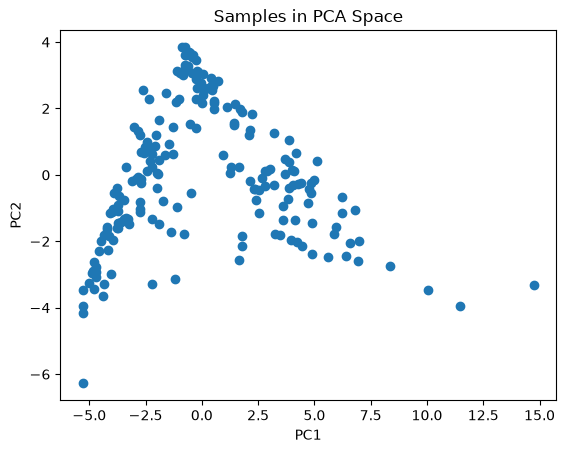

In [26]:
plt.scatter(X_pca[:,0], X_pca[:,1])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Samples in PCA Space")
plt.show()

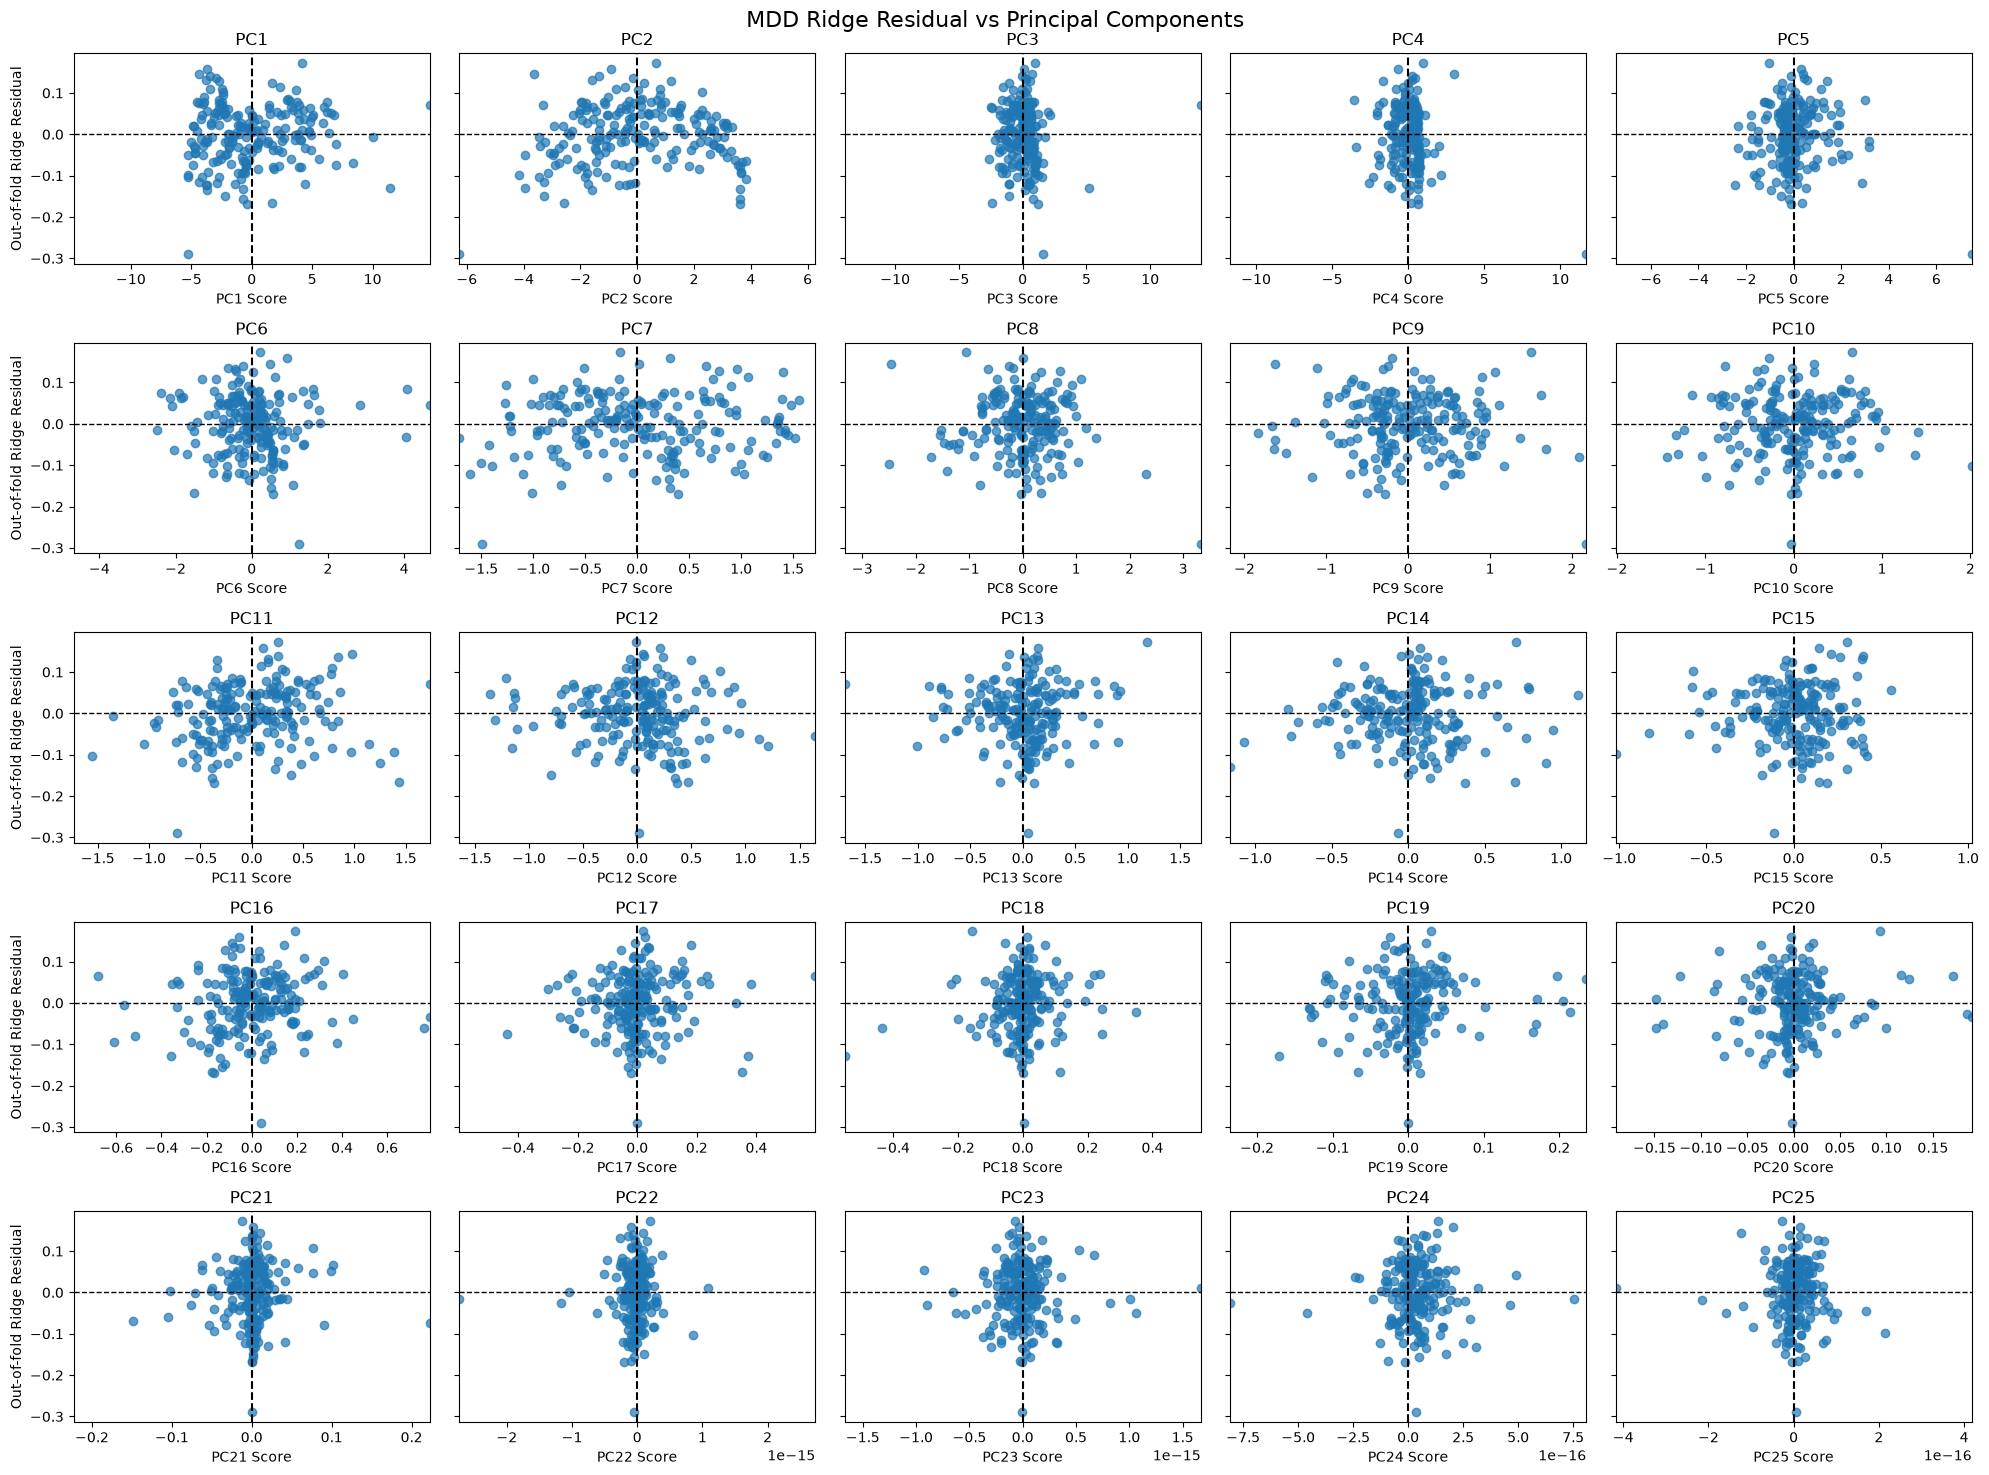

In [27]:
n_pcs = X_pca.shape[1]

n_cols = 5
n_rows = math.ceil(n_pcs / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(4*n_cols, 3*n_rows),
    sharey=True,
)

axes = axes.flatten()

for i in range(n_pcs):
    axes[i].scatter(
        X_pca[:, i],
        df_reg["mdd_ridge_res"],
        alpha=0.7
    )
    axes[i].axhline(0, linestyle="--", color="black", linewidth=1)
    axes[i].axvline(0, linestyle="--", color="black")

    max_abs = np.max(np.abs(X_pca[:, i]))
    axes[i].set_xlim(-max_abs, max_abs)
    
    axes[i].set_title(f"PC{i+1}")
    axes[i].set_xlabel(f"PC{i+1} Score")

# Only label the left-most plots
for ax in axes[::n_cols]:
    ax.set_ylabel("Out-of-fold Ridge Residual")

# Remove any unused axes
for j in range(n_pcs, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("MDD Ridge Residual vs Principal Components", fontsize=16)
plt.tight_layout()
plt.show()

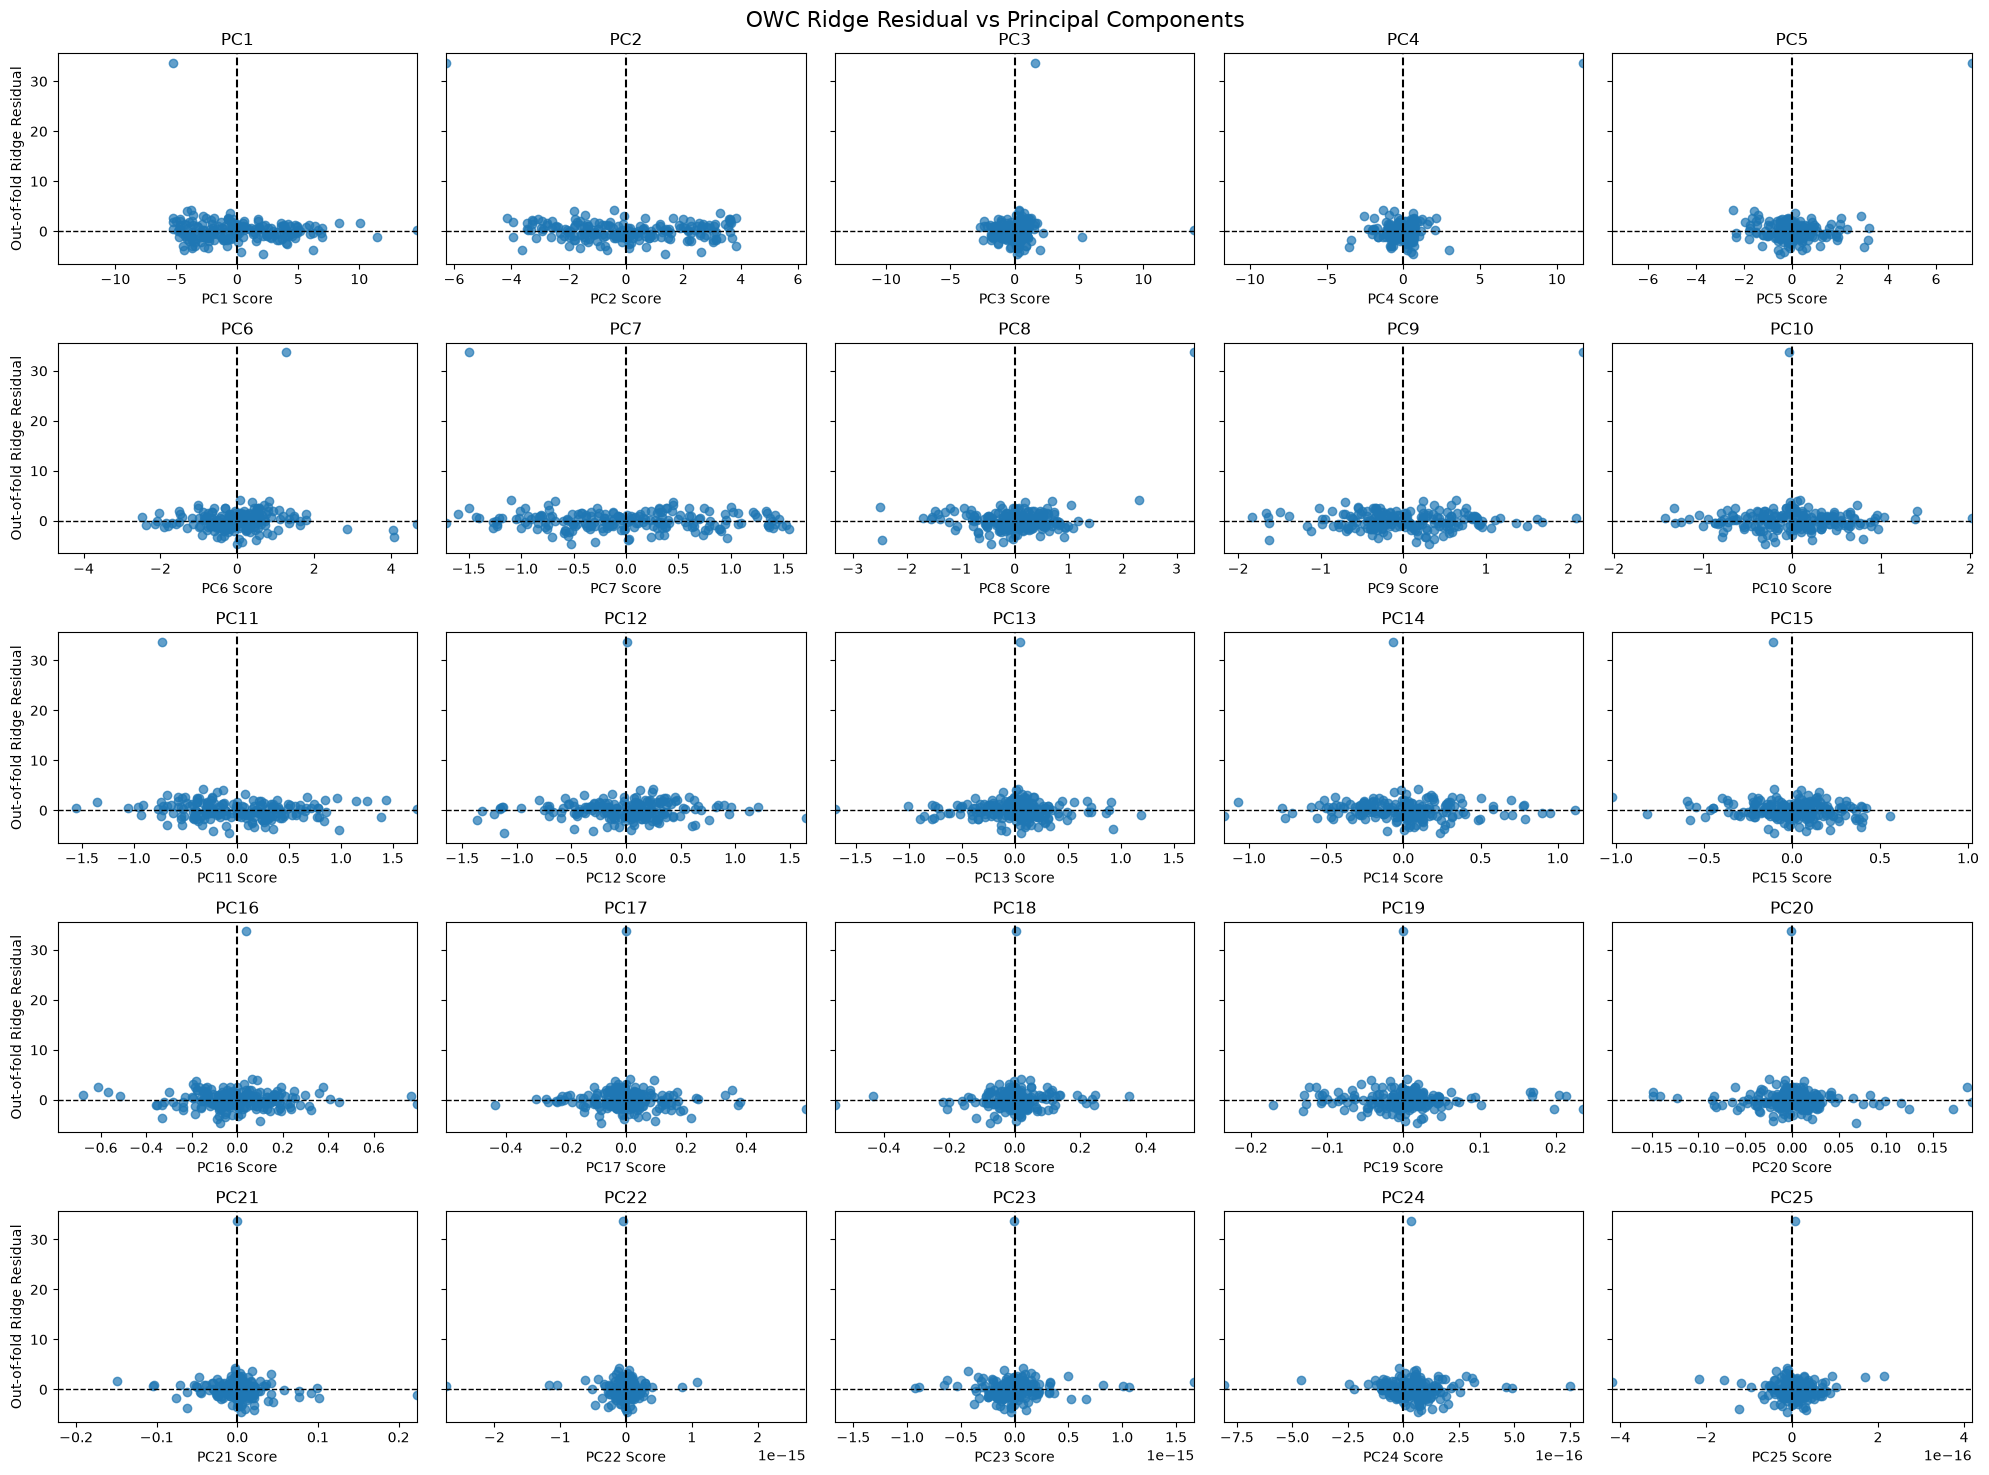

In [28]:
n_pcs = X_pca.shape[1]

n_cols = 5
n_rows = math.ceil(n_pcs / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(4*n_cols, 3*n_rows),
    sharey=True,
)

axes = axes.flatten()

for i in range(n_pcs):
    axes[i].scatter(
        X_pca[:, i],
        df_reg["owc_ridge_res"],
        alpha=0.7
    )
    axes[i].axhline(0, linestyle="--", color="black", linewidth=1)
    axes[i].axvline(0, linestyle="--", color="black")

    max_abs = np.max(np.abs(X_pca[:, i]))
    axes[i].set_xlim(-max_abs, max_abs)
    
    axes[i].set_title(f"PC{i+1}")
    axes[i].set_xlabel(f"PC{i+1} Score")

# Only label the left-most plots
for ax in axes[::n_cols]:
    ax.set_ylabel("Out-of-fold Ridge Residual")

# Remove any unused axes
for j in range(n_pcs, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("OWC Ridge Residual vs Principal Components", fontsize=16)
plt.tight_layout()
plt.show()

In [29]:
# "Does the Ridge residual change systematically as PC(n) changes?"
# spearmanr evaluates the strength and direction of the association between two ranked or continuous variables

results = []

residual_mdd = df_reg["mdd_ridge_res"]
residual_owc = df_reg["owc_ridge_res"]

for i in range(X_pca.shape[1]):
    rho_mdd, p_mdd = spearmanr(X_pca[:, i], residual_mdd)
    rho_owc, p_owc = spearmanr(X_pca[:, i], residual_owc)

    results.append({
        "PC": f"PC{i+1}",
        "rho_mdd": rho_mdd,
        "p_mdd": p_mdd,
        "rho_owc": rho_owc,
        "p_owc": p_owc,
    })

residual_pc_corr = (pd.DataFrame(results).set_index("PC").round(3))

residual_pc_corr

,rho_mdd,p_mdd,rho_owc,p_owc
PC,,,,
PC1,0.068,0.335,-0.006,0.936
PC2,0.052,0.464,-0.058,0.414
PC3,-0.097,0.172,0.113,0.111
PC4,-0.147,0.038,0.119,0.091
PC5,0.098,0.166,-0.089,0.207
PC6,-0.100,0.156,0.151,0.033
PC7,-0.012,0.867,-0.040,0.575
PC8,-0.002,0.972,-0.034,0.635
PC9,-0.014,0.843,-0.011,0.879


Linear latent structure exists and is captured well by Ridge. Residual analysis shows no remaining dependence on individual principal components.

## Nonlinearity
Are the remaining errors due to nonlinear relationships?

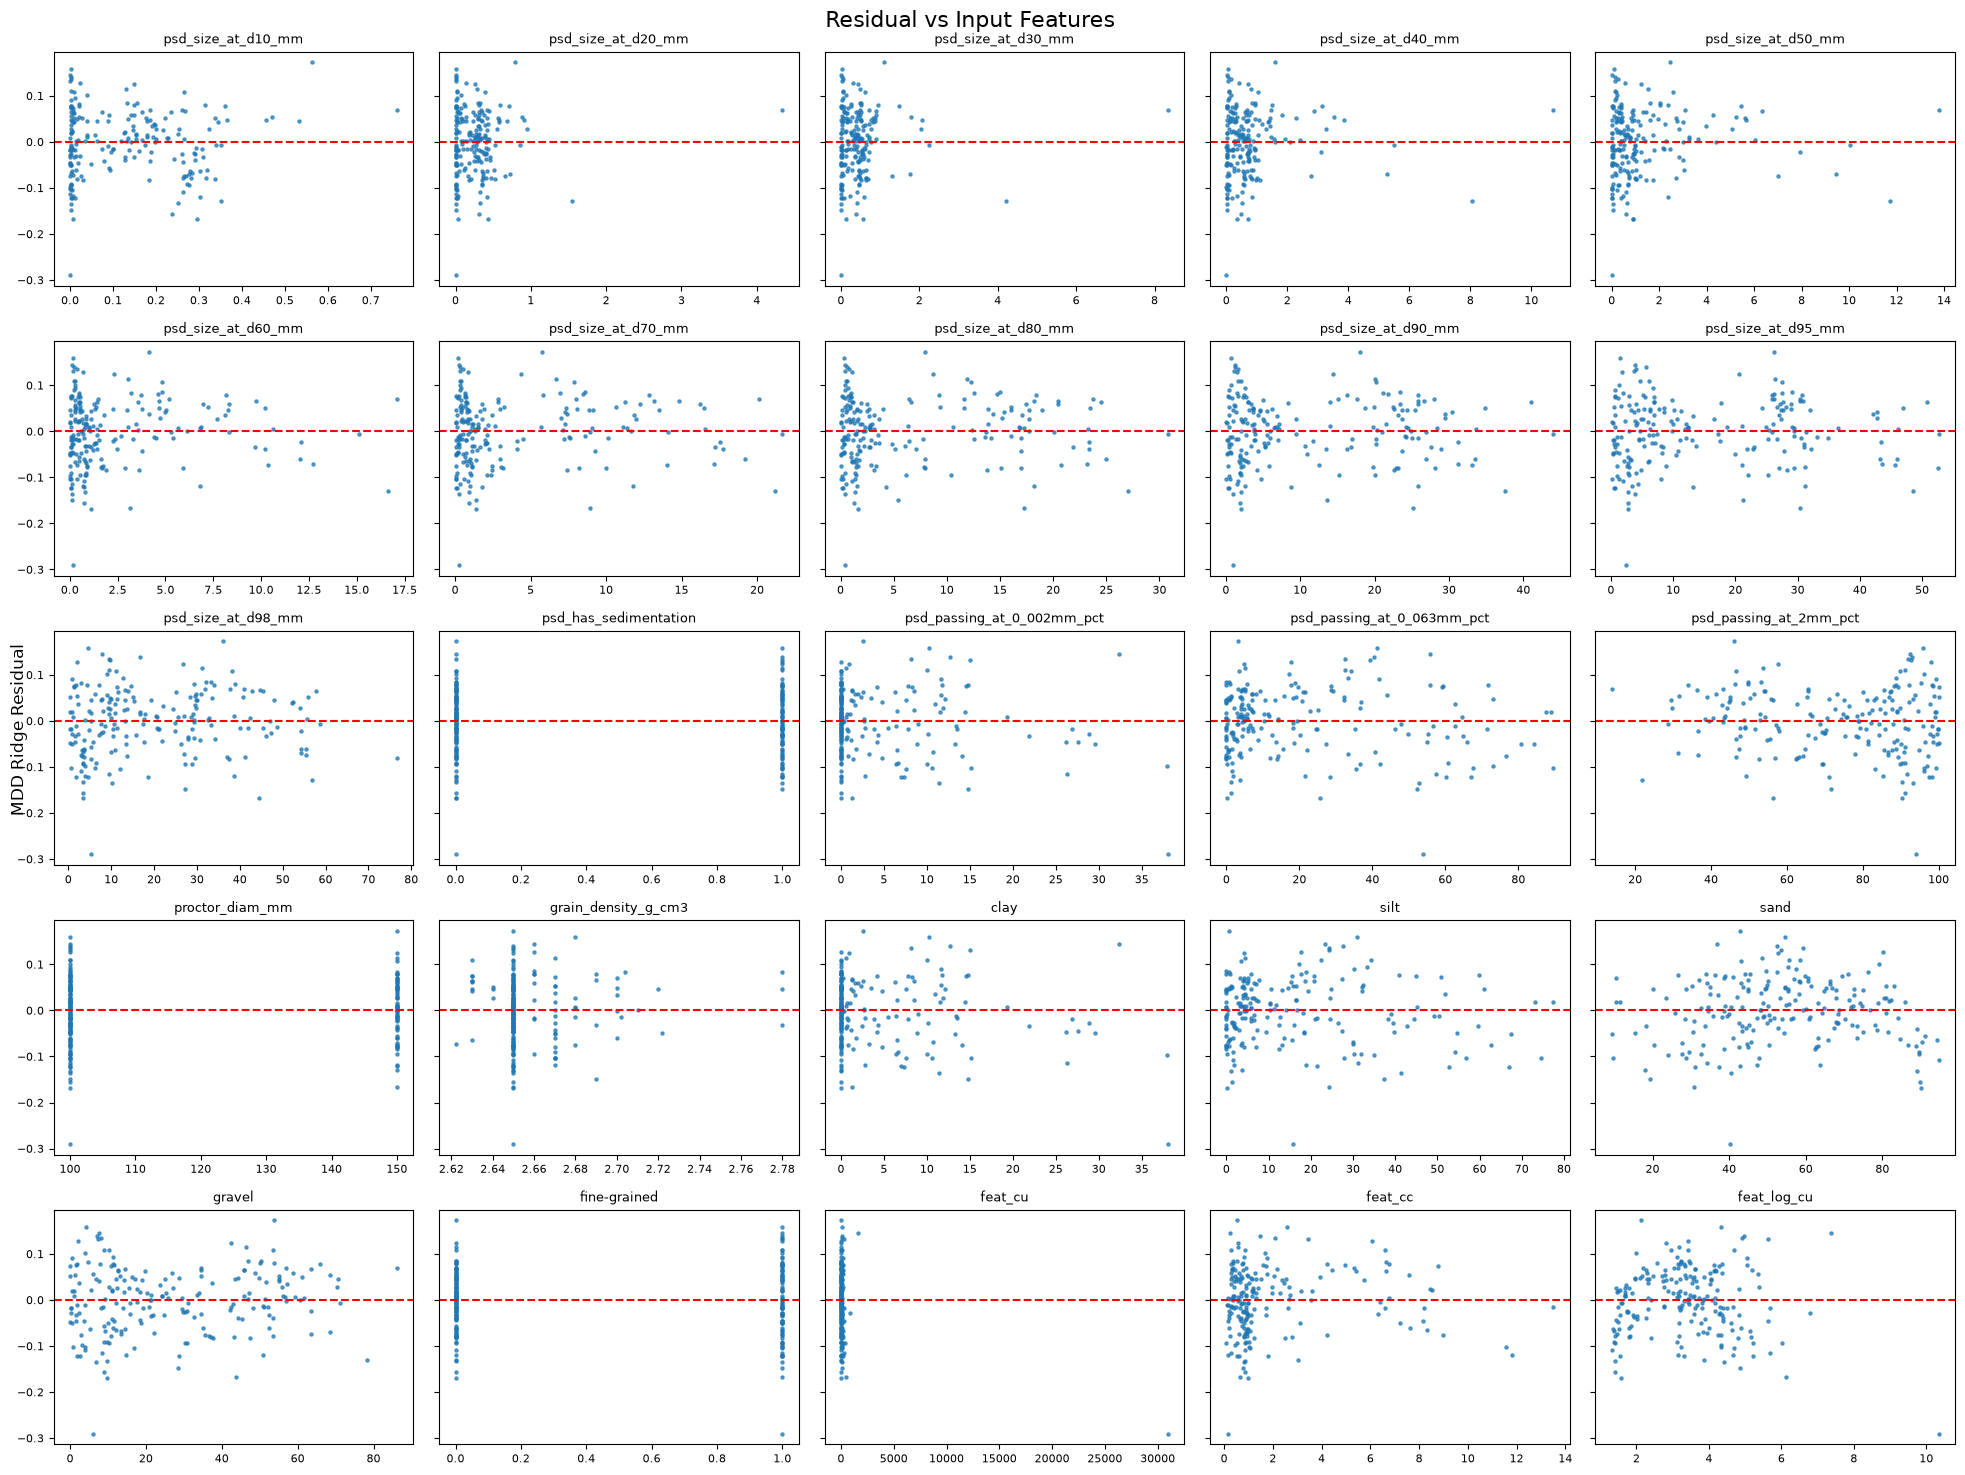

In [30]:
X = X[params_av]

n_features = len(X.columns)

n_cols = 5
n_rows = math.ceil(n_features / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(4*n_cols, 3*n_rows),
    sharey=True
)

axes = axes.flatten()

for i, col in enumerate(X.columns):
    axes[i].scatter(
        X[col],
        residual_mdd,
        alpha=0.7,
        s=5
    )
    axes[i].axhline(0, color="red", linestyle="--")
    axes[i].set_title(col, fontsize=9)
    axes[i].tick_params(labelsize=8)

# Remove empty subplots
for j in range(n_features, len(axes)):
    fig.delaxes(axes[j])

fig.supylabel("MDD Ridge Residual")
fig.suptitle("Residual vs Input Features", fontsize=16)

plt.tight_layout()
plt.show()

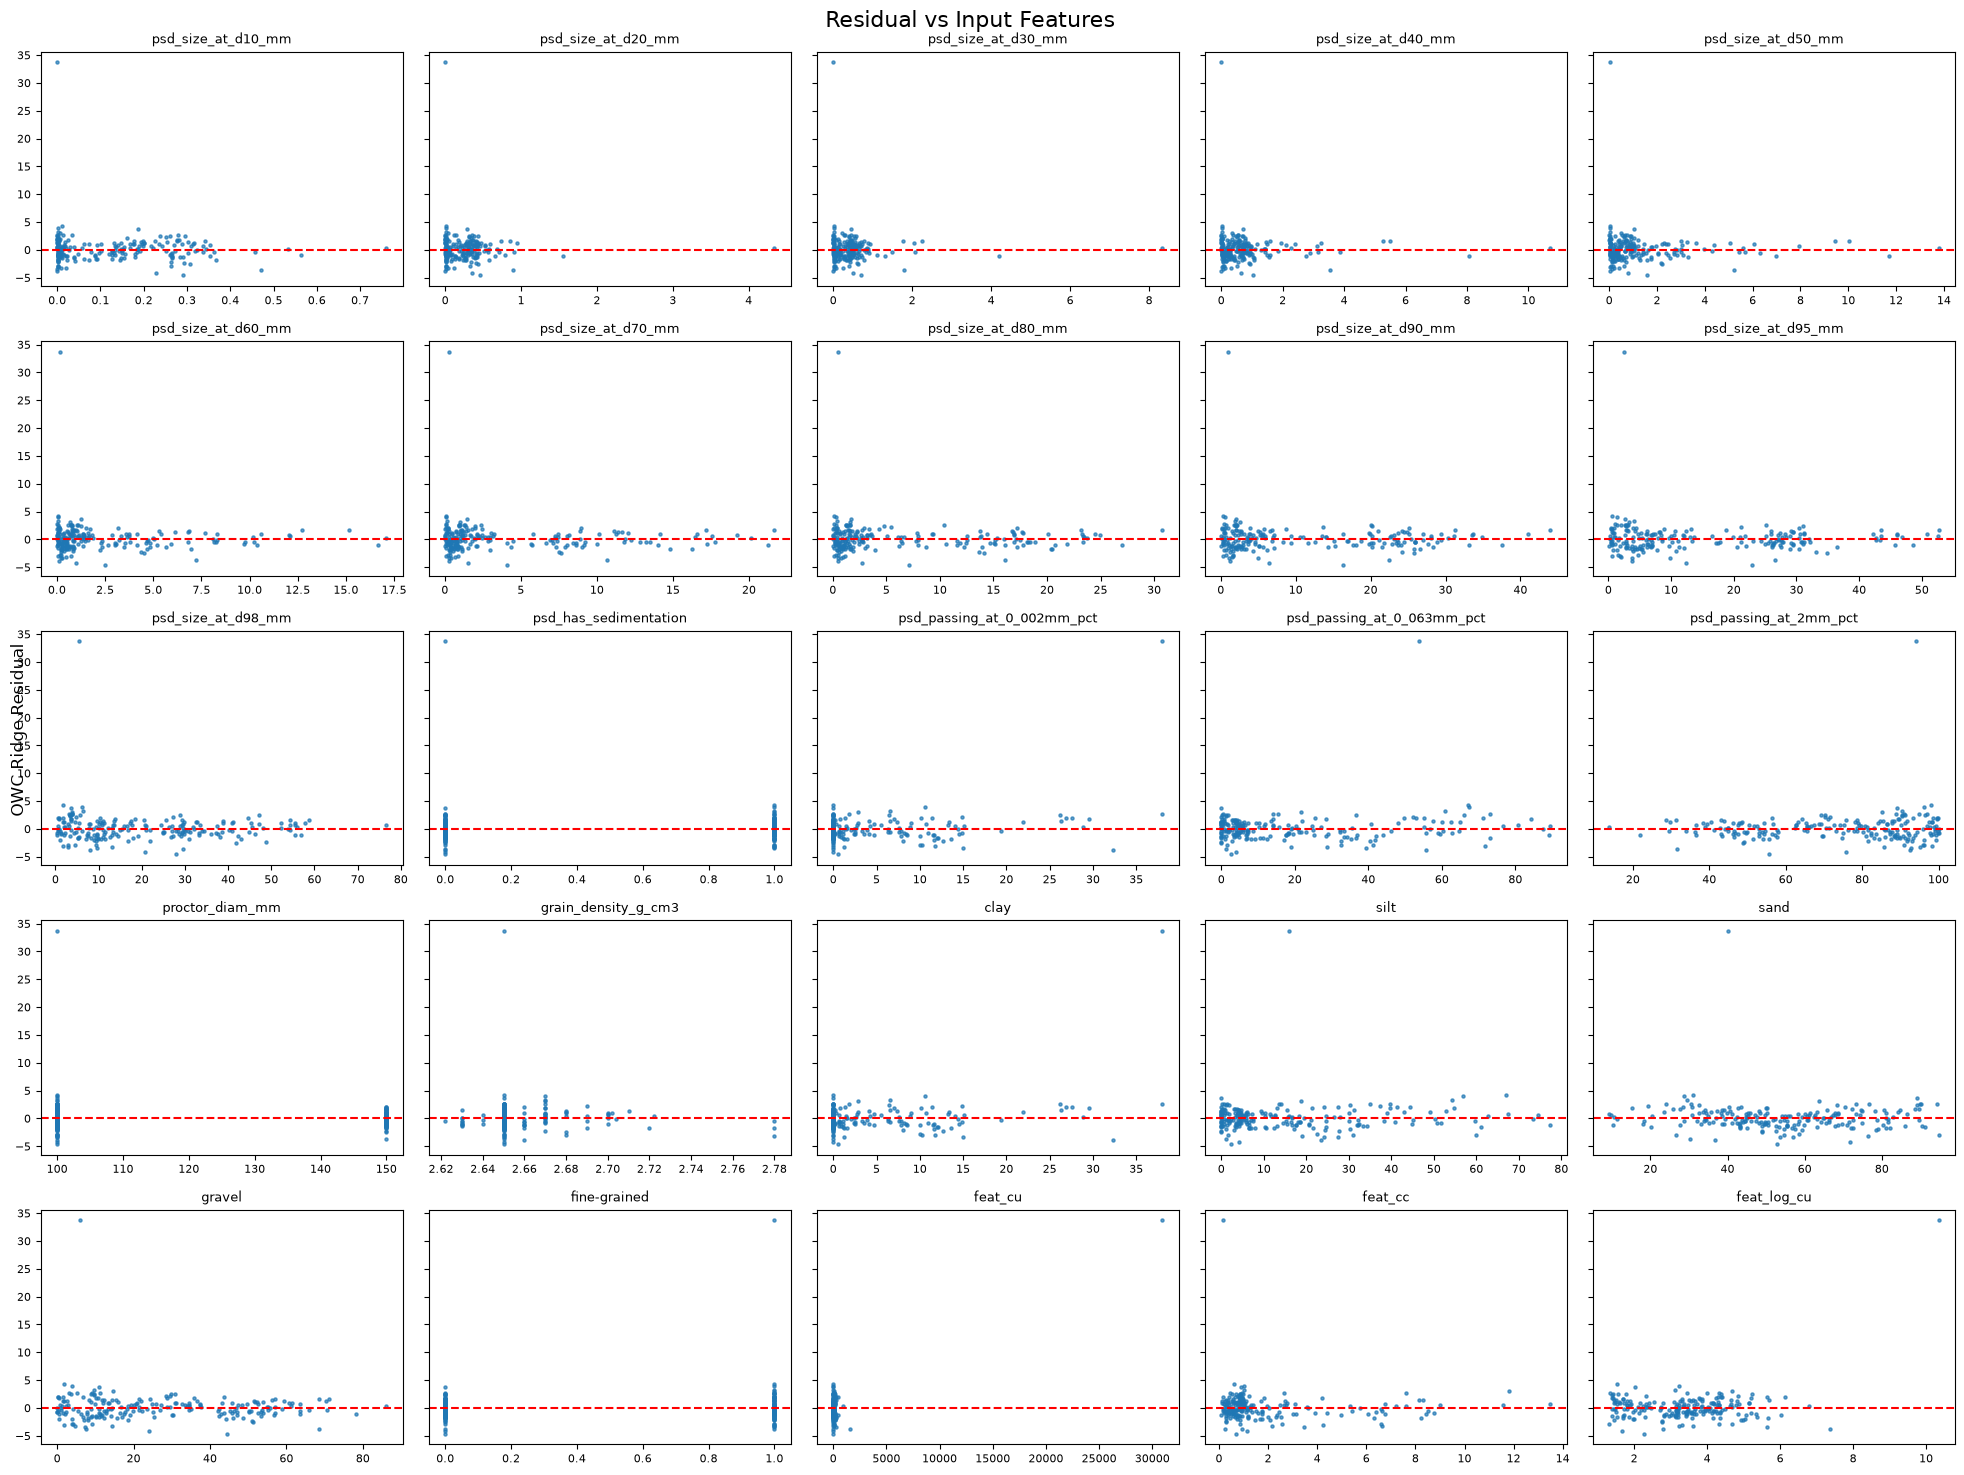

In [31]:
X = X[params_av]

n_features = len(X.columns)

n_cols = 5
n_rows = math.ceil(n_features / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(4*n_cols, 3*n_rows),
    sharey=True
)

axes = axes.flatten()

for i, col in enumerate(X.columns):
    axes[i].scatter(
        X[col],
        residual_owc,
        alpha=0.7,
        s=5
    )
    axes[i].axhline(0, color="red", linestyle="--")
    axes[i].set_title(col, fontsize=9)
    axes[i].tick_params(labelsize=8)

# Remove empty subplots
for j in range(n_features, len(axes)):
    fig.delaxes(axes[j])

fig.supylabel("OWC Ridge Residual")
fig.suptitle("Residual vs Input Features", fontsize=16)

plt.tight_layout()
plt.show()

### XGBoost

In [32]:
feature_cols = [
    col for col in params_av
    if col not in [
        "proctor_mdd_g_cm3",
        "proctor_owc_pct"
    ]
]

X = df[feature_cols].copy()

y_mdd = df["proctor_mdd_g_cm3"].copy()
y_owc = df["proctor_owc_pct"].copy()

In [33]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

results = []

xgb_mdd_oof = np.full(len(X), np.nan)
xgb_owc_oof = np.full(len(X), np.nan)

for fold, (train_idx, val_idx) in enumerate(cv.split(X), start=1):

    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]

    y_mdd_train = y_mdd.iloc[train_idx]
    y_mdd_val = y_mdd.iloc[val_idx]

    y_owc_train = y_owc.iloc[train_idx]
    y_owc_val = y_owc.iloc[val_idx]

    # Conservative baseline to reduce overfitting on a small dataset
    mdd_model = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=300,
        learning_rate=0.03,
        max_depth=3,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.0,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1
    )

    owc_model = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=300,
        learning_rate=0.03,
        max_depth=3,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.0,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1
    )

    mdd_model.fit(X_train, y_mdd_train)
    owc_model.fit(X_train, y_owc_train)

    mdd_train_pred = mdd_model.predict(X_train)
    mdd_val_pred = mdd_model.predict(X_val)

    owc_train_pred = owc_model.predict(X_train)
    owc_val_pred = owc_model.predict(X_val)

    xgb_mdd_oof[val_idx] = mdd_val_pred
    xgb_owc_oof[val_idx] = owc_val_pred

    results.append({
        "Fold": f"Fold {fold}",
        "MDD train R2 (xgb)": r2_score(y_mdd_train, mdd_train_pred),
        "MDD val R2 (xgb)": r2_score(y_mdd_val, mdd_val_pred),
        "OWC train R2 (xgb)": r2_score(y_owc_train, owc_train_pred),
        "OWC val R2 (xgb)": r2_score(y_owc_val, owc_val_pred)
    })

results_df = pd.DataFrame(results).set_index("Fold")

In [34]:
results_df.loc["Mean"] = results_df.mean()
results_df.loc["Std"] = results_df.iloc[:-1].std()

results_df.round(4)

,MDD train R2 (xgb),MDD val R2 (xgb),OWC train R2 (xgb),OWC val R2 (xgb)
Fold,,,,
Fold 1,0.9832,0.8323,0.9825,0.7523
Fold 2,0.9839,0.7836,0.9778,0.8575
Fold 3,0.9842,0.8286,0.9791,0.7709
Fold 4,0.9818,0.8776,0.9775,0.7662
Fold 5,0.9841,0.8528,0.9778,0.8379
Mean,0.9834,0.8350,0.9790,0.7970
Std,0.0010,0.0347,0.0021,0.0473


In [35]:
df_reg['mdd_xgb'] = xgb_mdd_oof
df_reg['owc_xgb'] = xgb_owc_oof
df_reg['mdd_xgb_res'] = df_reg['proctor_mdd_g_cm3'] - df_reg['mdd_xgb']
df_reg['owc_xgb_res'] = df_reg['proctor_owc_pct'] - df_reg['owc_xgb']
df_reg['mdd_xgb_res_pct'] = (df_reg['proctor_mdd_g_cm3'] - df_reg['mdd_xgb']) / df_reg['proctor_mdd_g_cm3']
df_reg['owc_xgb_res_pct'] = (df_reg['proctor_owc_pct'] - df_reg['owc_xgb']) / df_reg['proctor_owc_pct']

#### Feature Importance

In [36]:
def make_xgb_model():
    return XGBRegressor(
        objective="reg:squarederror",
        n_estimators=300,
        learning_rate=0.03,
        max_depth=3,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.0,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1
    )

xgb_mdd = make_xgb_model()
xgb_owc = make_xgb_model()

xgb_mdd.fit(X, y_mdd)
xgb_owc.fit(X, y_owc)

def get_gain_importance(model, feature_names):
    gain_dict = model.get_booster().get_score(importance_type="gain")

    importance = pd.Series({feature: gain_dict.get(feature, 0.0) for feature in feature_names}, name="gain")

    # Convert raw gains into proportions
    if importance.sum() > 0:
        importance = importance / importance.sum()

    return importance.sort_values(ascending=False)

mdd_gain = get_gain_importance(xgb_mdd, X.columns)
owc_gain = get_gain_importance(xgb_owc, X.columns)

print("MDD gain importance")
display(mdd_gain.to_frame().head(15))

print("OWC gain importance")
display(owc_gain.to_frame().head(15))

MDD gain importance


,gain
psd_size_at_d70_mm,0.172751
psd_size_at_d90_mm,0.108478
psd_size_at_d60_mm,0.101136
psd_size_at_d95_mm,0.089806
psd_size_at_d98_mm,0.087436
psd_size_at_d50_mm,0.080921
feat_cc,0.048516
feat_cu,0.048241
psd_size_at_d40_mm,0.039397
psd_passing_at_2mm_pct,0.028967


OWC gain importance


,gain
psd_size_at_d50_mm,0.269005
psd_size_at_d40_mm,0.187569
psd_passing_at_0_063mm_pct,0.141034
psd_size_at_d70_mm,0.072143
psd_size_at_d60_mm,0.062663
psd_size_at_d30_mm,0.052314
psd_passing_at_2mm_pct,0.031689
psd_size_at_d80_mm,0.022822
psd_size_at_d98_mm,0.021617
silt,0.018158


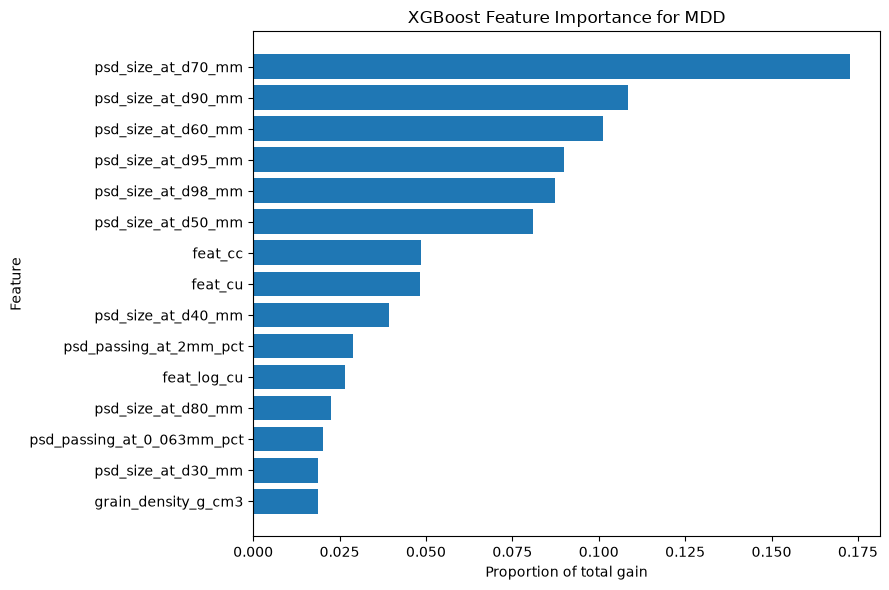

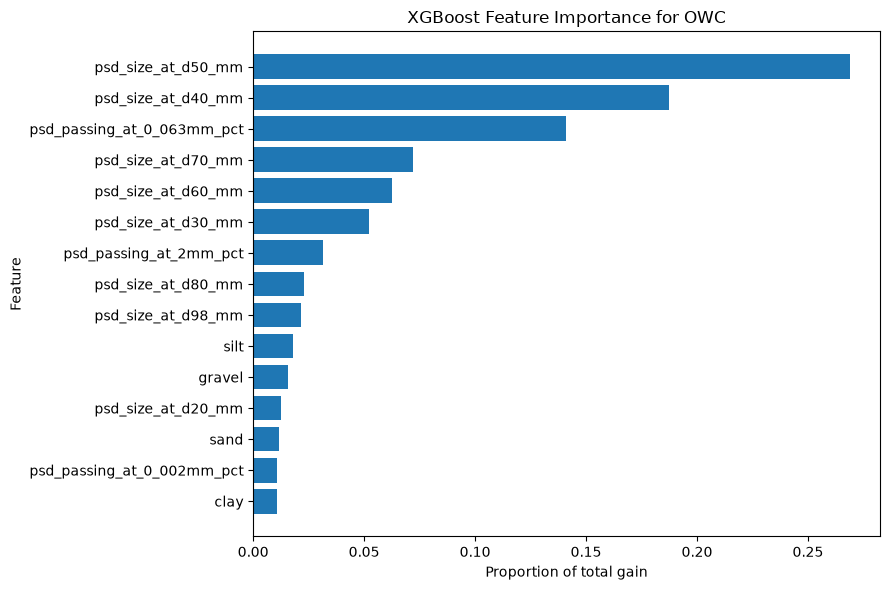

,MDD gain,OWC gain
feat_cu,0.048241,0.006469
feat_cc,0.048516,0.010555
feat_log_cu,0.026623,0.007105


In [37]:
def plot_gain_importance(
    importance,
    title,
    top_n=15
):
    top = importance.head(top_n).sort_values()

    plt.figure(figsize=(9, 6))
    plt.barh(top.index, top.values)

    plt.xlabel("Proportion of total gain")
    plt.ylabel("Feature")
    plt.title(title)

    plt.tight_layout()
    plt.show()

plot_gain_importance(mdd_gain, "XGBoost Feature Importance for MDD")
plot_gain_importance(owc_gain, "XGBoost Feature Importance for OWC")

engineered_features = ["feat_cu", "feat_cc", "feat_log_cu"]

engineered_importance = pd.DataFrame({
    "MDD gain": mdd_gain.reindex(engineered_features, fill_value=0),
    "OWC gain": owc_gain.reindex(engineered_features, fill_value=0)
})

engineered_importance

#### SHAP

In [38]:
mdd_explainer = shap.TreeExplainer(xgb_mdd)
owc_explainer = shap.TreeExplainer(xgb_owc)

mdd_shap_values = mdd_explainer(X)
owc_shap_values = owc_explainer(X)

In [39]:
def plot_shap_summary(model, X, target_name, max_display=15):
    explainer = shap.TreeExplainer(model)
    shap_values = explainer(X)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # Beeswarm
    shap.plots.beeswarm(shap_values, max_display=max_display, show=False, ax=axes[0], plot_size=None)
    axes[0].set_title(f"SHAP Summary Plot for {target_name}")

    # Global bar importance
    shap.plots.bar(shap_values, max_display=max_display, show=False, ax=axes[1])
    axes[1].set_title(f"Global SHAP Importance for {target_name}")

    plt.tight_layout()
    plt.show()

    return shap_values

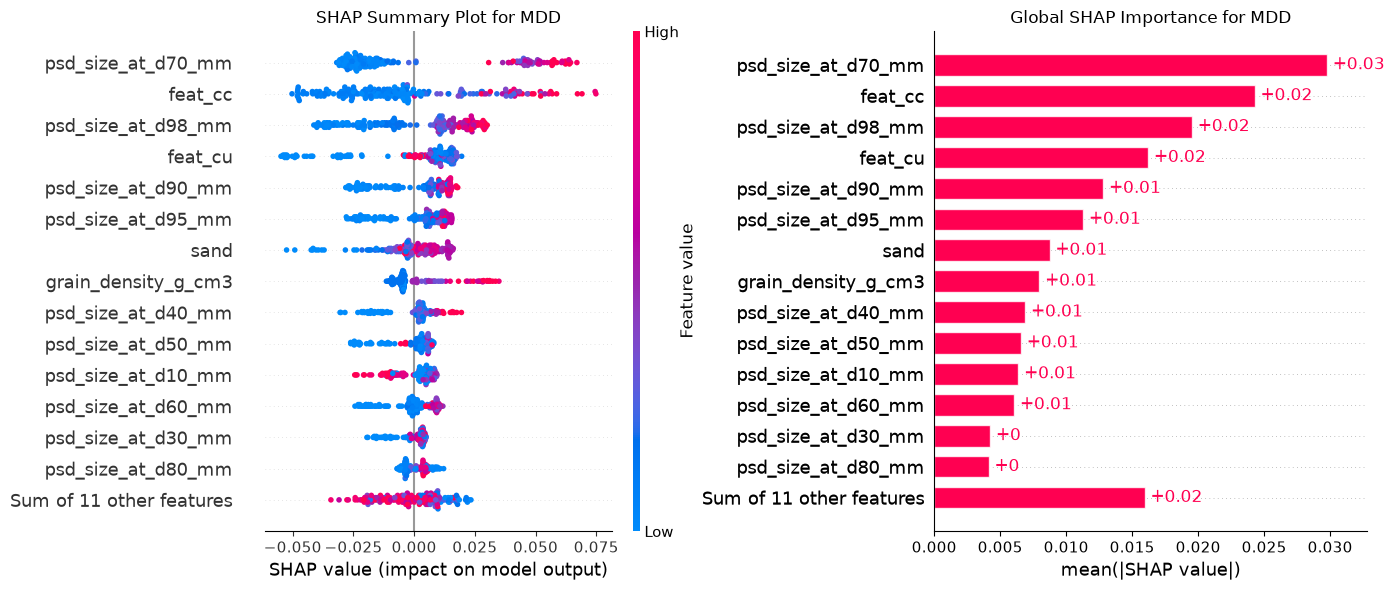

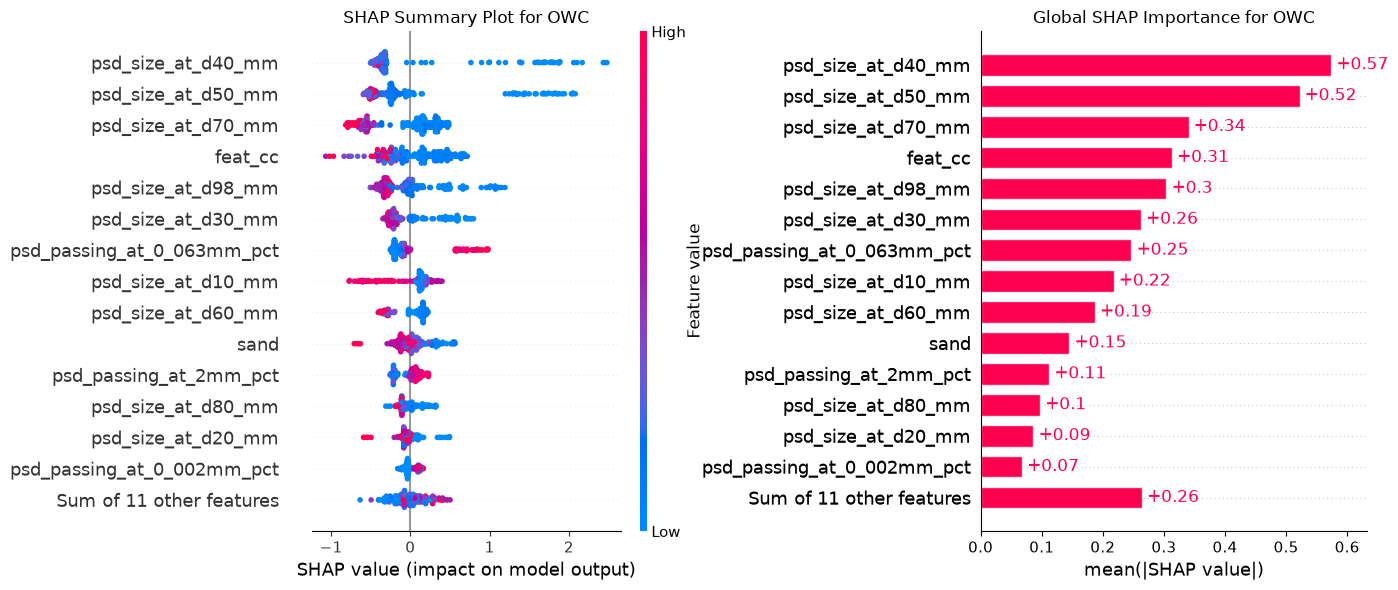

In [40]:
mdd_shap_values = plot_shap_summary(xgb_mdd, X, target_name="MDD")
owc_shap_values = plot_shap_summary(xgb_owc, X, target_name="OWC")

### Gaussian Process Regression

In [41]:
feature_cols = [
    col for col in params_av
    if col not in [
        "proctor_mdd_g_cm3",
        "proctor_owc_pct"
    ]
]

X = df[feature_cols].copy()
X = X.replace([np.inf, -np.inf], np.nan)

y_mdd = df["proctor_mdd_g_cm3"].copy()
y_owc = df["proctor_owc_pct"].copy()

In [42]:
def make_gpr_model(n_features):
    kernel = (
        ConstantKernel(constant_value=1.0, constant_value_bounds=(1e-2, 1e2))
        * RBF(length_scale=np.ones(n_features), length_scale_bounds=(1e-2, 1e2))
        + WhiteKernel(noise_level=0.1, noise_level_bounds=(1e-5, 1e1))
    )

    return GaussianProcessRegressor(kernel=kernel, alpha=1e-8, normalize_y=False, n_restarts_optimizer=3, random_state=42)

In [43]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

results = []

gpr_mdd_oof = np.full(len(X), np.nan)
gpr_owc_oof = np.full(len(X), np.nan)
mdd_oof_std = np.full(len(X), np.nan)
owc_oof_std = np.full(len(X), np.nan)

for fold, (train_idx, val_idx) in enumerate(cv.split(X), start=1):

    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]

    y_mdd_train = y_mdd.iloc[train_idx]
    y_mdd_val = y_mdd.iloc[val_idx]

    y_owc_train = y_owc.iloc[train_idx]
    y_owc_val = y_owc.iloc[val_idx]

    # Preprocess X
    x_preprocessor = Pipeline([("scaler", StandardScaler())])

    X_train_scaled = x_preprocessor.fit_transform(X_train)
    X_val_scaled = x_preprocessor.transform(X_val)

    # Standardize targets
    mdd_scaler = StandardScaler()
    owc_scaler = StandardScaler()

    y_mdd_train_scaled = mdd_scaler.fit_transform(y_mdd_train.to_numpy().reshape(-1, 1)).ravel()
    y_owc_train_scaled = owc_scaler.fit_transform(y_owc_train.to_numpy().reshape(-1, 1)).ravel()

    # Fit GPR models
    gpr_mdd = make_gpr_model(n_features=X_train_scaled.shape[1])
    gpr_owc = make_gpr_model(n_features=X_train_scaled.shape[1])
    gpr_mdd.fit(X_train_scaled, y_mdd_train_scaled)
    gpr_owc.fit(X_train_scaled, y_owc_train_scaled)

    # Predictions
    mdd_train_pred_scaled = gpr_mdd.predict(X_train_scaled)
    mdd_val_pred_scaled, mdd_val_std_scaled = (gpr_mdd.predict(X_val_scaled, return_std=True))
    owc_train_pred_scaled = gpr_owc.predict(X_train_scaled)
    owc_val_pred_scaled, owc_val_std_scaled = (gpr_owc.predict(X_val_scaled, return_std=True))

    # Transform predictions back to original units
    mdd_train_pred = mdd_scaler.inverse_transform(mdd_train_pred_scaled.reshape(-1, 1)).ravel()
    mdd_val_pred = mdd_scaler.inverse_transform(mdd_val_pred_scaled.reshape(-1, 1)).ravel()
    owc_train_pred = owc_scaler.inverse_transform(owc_train_pred_scaled.reshape(-1, 1)).ravel()
    owc_val_pred = owc_scaler.inverse_transform(owc_val_pred_scaled.reshape(-1, 1)).ravel()

    gpr_mdd_oof[val_idx] = mdd_val_pred
    gpr_owc_oof[val_idx] = owc_val_pred

    # Convert predictive standard deviation back to target units
    mdd_val_std = (mdd_val_std_scaled * mdd_scaler.scale_[0])
    owc_val_std = (owc_val_std_scaled * owc_scaler.scale_[0])
    mdd_oof_std[val_idx] = mdd_val_std
    owc_oof_std[val_idx] = owc_val_std

    results.append({
        "Fold": f"Fold {fold}",
        "MDD train R2 (gpr)": r2_score(y_mdd_train, mdd_train_pred),
        "MDD val R2 (gpr)": r2_score(y_mdd_val, mdd_val_pred),
        "MDD val RMSE (gpr)": mean_squared_error(y_mdd_val, mdd_val_pred) ** 0.5,
        "MDD mean pred std": mdd_val_std.mean(),
        "OWC train R2 (gpr)": r2_score(y_owc_train, owc_train_pred),
        "OWC val R2 (gpr)": r2_score(y_owc_val, owc_val_pred),
        "OWC val RMSE (gpr)": mean_squared_error(y_owc_val, owc_val_pred) ** 0.5,
        "OWC mean pred std": owc_val_std.mean()
    })

df_reg["mdd_gpr"] = gpr_mdd_oof
df_reg["owc_gpr"] = gpr_owc_oof

df_reg["mdd_gpr_std"] = mdd_oof_std
df_reg["owc_gpr_std"] = owc_oof_std

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 4 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 4 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 4 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 4 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 5 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

In [44]:
df_reg[["mdd_gpr", "owc_gpr", "mdd_gpr_std", "owc_gpr_std"]].isna().sum()

mdd_gpr        0
owc_gpr        0
mdd_gpr_std    0
owc_gpr_std    0
dtype: int64

In [45]:
gpr_results_df = pd.DataFrame(results).set_index("Fold")

gpr_results_df.loc["Mean"] = gpr_results_df.mean()
gpr_results_df.loc["Std"] = (
    gpr_results_df.iloc[:-1].std()
)

gpr_results_df.round(4)

,MDD train R2 (gpr),MDD val R2 (gpr),MDD val RMSE (gpr),MDD mean pred std,OWC train R2 (gpr),OWC val R2 (gpr),OWC val RMSE (gpr),OWC mean pred std
Fold,,,,,,,,
Fold 1,0.9261,0.8109,0.0605,0.0480,0.8837,0.7670,1.4898,1.3032
Fold 2,0.9223,0.8236,0.0569,0.0534,0.8833,0.8319,1.3397,1.4474
Fold 3,0.9298,0.7471,0.0707,0.0493,0.8975,0.6556,1.9867,1.3663
Fold 4,0.9118,0.8278,0.0612,0.0529,0.8735,0.7124,2.0553,1.3786
Fold 5,0.9268,0.8630,0.0479,0.0489,0.8817,0.8088,1.3170,1.3706
Mean,0.9233,0.8145,0.0594,0.0505,0.8840,0.7552,1.6377,1.3732
Std,0.0070,0.0423,0.0082,0.0025,0.0086,0.0718,0.3569,0.0512


In [46]:
df_reg['mdd_gpr'] = gpr_mdd_oof
df_reg['owc_gpr'] = gpr_owc_oof
df_reg['mdd_gpr_res'] = df_reg['proctor_mdd_g_cm3'] - df_reg['mdd_gpr']
df_reg['owc_gpr_res'] = df_reg['proctor_owc_pct'] - df_reg['owc_gpr']
df_reg['mdd_gpr_res_pct'] = (df_reg['proctor_mdd_g_cm3'] - df_reg['mdd_gpr']) / df_reg['proctor_mdd_g_cm3']
df_reg['owc_gpr_res_pct'] = (df_reg['proctor_owc_pct'] - df_reg['owc_gpr']) / df_reg['proctor_owc_pct']

### Linear Models vs Nonlinear Models

In [47]:
comparison = pd.DataFrame({
    "MDD mean val R2": {
        "Linear": cv_results_lin.loc["Mean", "MDD val R2 (lin)"],
        "Ridge": cv_results_lin.loc["Mean", "MDD val R2 (rid)"],
        "XGBoost": results_df.loc["Mean", "MDD val R2 (xgb)"],
        "GPR": gpr_results_df.loc["Mean", "MDD val R2 (gpr)"]
    },
    "OWC mean val R2": {
        "Linear": cv_results_lin.loc["Mean", "OWC val R2 (lin)"],
        "Ridge": cv_results_lin.loc["Mean", "OWC val R2 (rid)"],
        "XGBoost": results_df.loc["Mean", "OWC val R2 (xgb)"],
        "GPR": gpr_results_df.loc["Mean", "OWC val R2 (gpr)"]
    },
    "MDD val std": {
        "Linear": cv_results_lin.loc["Std", "MDD val R2 (lin)"],
        "Ridge": cv_results_lin.loc["Std", "MDD val R2 (rid)"],
        "XGBoost": results_df.loc["Std", "MDD val R2 (xgb)"],
        "GPR": gpr_results_df.loc["Std", "MDD val R2 (gpr)"]
    },
    "OWC val std": {
        "Linear": cv_results_lin.loc["Std", "OWC val R2 (lin)"],
        "Ridge": cv_results_lin.loc["Std", "OWC val R2 (rid)"],
        "XGBoost": results_df.loc["Std", "OWC val R2 (xgb)"],
        "GPR": gpr_results_df.loc["Std", "OWC val R2 (gpr)"]
    }
})

comparison.round(4)

,MDD mean val R2,OWC mean val R2,MDD val std,OWC val std
Linear,0.7440,0.3018,0.0824,0.8789
Ridge,0.7354,0.3877,0.0353,0.7357
XGBoost,0.8350,0.7970,0.0347,0.0473
GPR,0.8145,0.7552,0.0423,0.0718


## Information learned by the models

In [48]:
for c in df_reg.columns:
    if c.endswith('res_pct'):
        df_reg[f'{c}_abs'] = abs(df_reg[c])

In [49]:
col_res_pct = ['mdd_lin_res_pct', 'owc_lin_res_pct', 'mdd_ridge_res_pct', 'owc_ridge_res_pct', 
               'mdd_xgb_res_pct', 'owc_xgb_res_pct','mdd_gpr_res_pct', 'owc_gpr_res_pct']

col_na = ['hyd_cond_kf_m_s', 'hyd_cond_hyd_gradient', 'atterberg_liquid_limit_pct', 
          'atterberg_plastic_limit_pct', 'loss_on_ignition_pct', 'feat_pi']

df_reg[col_res_pct]

,mdd_lin_res_pct,owc_lin_res_pct,mdd_ridge_res_pct,owc_ridge_res_pct,mdd_xgb_res_pct,owc_xgb_res_pct,mdd_gpr_res_pct,owc_gpr_res_pct
0,-0.015050,0.092223,-0.008213,0.073196,-0.010527,0.095873,-0.020860,0.154530
1,-0.027484,0.067069,-0.015498,0.043058,0.011299,-0.038686,0.000254,0.075321
2,-0.023342,0.063798,-0.024398,0.035775,0.000294,0.095337,0.018407,0.107657
3,-0.011251,0.033067,-0.030174,0.088608,-0.048546,0.093186,-0.013887,0.057014
4,-0.046616,0.009810,-0.056446,0.034365,0.016264,-0.036264,-0.095026,0.369576
...,...,...,...,...,...,...,...,...
196,-0.015418,0.060067,-0.007608,-0.028184,-0.021613,-0.006983,-0.015595,-0.033624
197,-0.022779,-0.263809,-0.030166,-0.197195,0.044721,-0.402556,0.021807,-0.383742
198,0.031581,0.043306,0.025630,0.107399,0.016587,0.093902,0.012970,0.114359
199,-0.017576,0.091757,-0.026909,0.131961,-0.001712,0.052363,-0.001276,0.065988


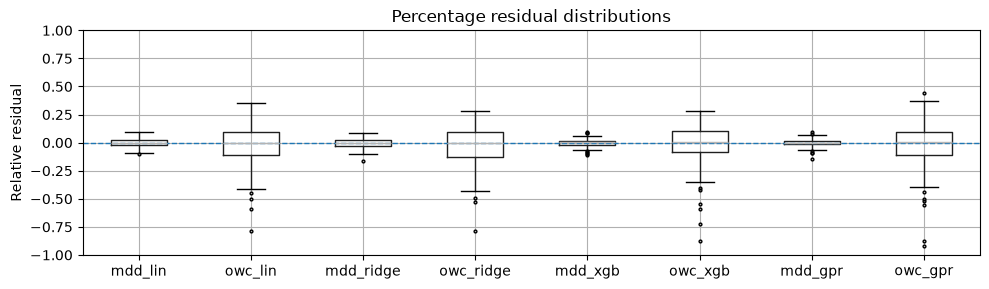

In [50]:
plt.figure(figsize=(10, 3))

df_reg[col_res_pct].boxplot(
    flierprops=dict(marker='o', markersize=2)
)

plt.axhline(0, linestyle="--", linewidth=1)
plt.ylim(-1, 1)

labels = [col.replace("_res_pct", "") for col in col_res_pct]
plt.xticks(range(1, len(labels) + 1), labels)

plt.ylabel("Relative residual")
plt.title("Percentage residual distributions")
plt.tight_layout()
plt.show()

In [51]:
for c in df.columns:
    if len(df[df[c].isna()]) > 0:
       print(c.ljust(30), len(df[df[c].isna()]))

hyd_cond_kf_m_s                140
hyd_cond_hyd_gradient          140
atterberg_liquid_limit_pct     175
atterberg_plastic_limit_pct    175
loss_on_ignition_pct           140
feat_pi                        175


In [ ]:
len(df[df['atterberg_liquid_limit_pct'].notna() & df['atterberg_plastic_limit_pct'].notna() & df['loss_on_ignition_pct'].notna() & df['fine-grained']])

19

## Imputation

In [165]:
col_na

['hyd_cond_kf_m_s',
 'hyd_cond_hyd_gradient',
 'atterberg_liquid_limit_pct',
 'atterberg_plastic_limit_pct',
 'loss_on_ignition_pct',
 'feat_pi']

### Imputation Reliability

Before incorporating imputed laboratory measurements into the predictive models, we evaluate whether the missing variables themselves could be reliably reconstructed from universally available measurements.

Conclusion: The predictive imputation models demonstrated that both hydraulic conductivity and loss on ignition can be reliably estimated from the remaining soil parameters, achieving out-of-fold $R^2$ values of 0.754 and 0.807, respectively. Loss on ignition exhibited substantially lower prediction errors (RMSE = 0.171 log units) than hydraulic conductivity (RMSE = 1.145 log units), indicating that it is more strongly explained by the available features. The larger residuals and error factors for hydraulic conductivity reflect its much wider dynamic range and greater inherent variability, with some predictions differing by several orders of magnitude. In contrast, loss on ignition predictions were generally much more stable, with most estimates lying within approximately a factor of 1.4 of the observed values. Overall, these results suggest that both variables are predictable from the existing measurements, although hydraulic conductivity is intrinsically more difficult to recover accurately than loss on ignition.

In [166]:
TARGET_COLS = ["hyd_cond_kf_m_s", "loss_on_ignition_pct"]

results = {}

for target_col in TARGET_COLS:
    predictors = [col for col in params_av if col != target_col]
    observed_mask = (df[target_col].notna() & np.isfinite(df[target_col]) & (df[target_col] > 0))

    X_reliability = df.loc[observed_mask, predictors].copy()
    y_log = np.log10(df.loc[observed_mask, target_col].astype(float))

    assert X_reliability.notna().all().all()

    cv = KFold(n_splits=5, shuffle=True, random_state=42)

    model = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=400,
        learning_rate=0.03,
        max_depth=3,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.0,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1
    )

    oof_log = cross_val_predict(estimator=model, X=X_reliability, y=y_log, cv=cv, method="predict")

    validation = df.loc[observed_mask].copy()

    validation["observed_log10"] = y_log.to_numpy()
    validation["oof_log10"] = oof_log
    validation["log_residual"] = (validation["observed_log10"] - validation["oof_log10"])
    validation["error_factor"] = (10 ** np.abs(validation["log_residual"]))

    results[target_col] = {
        "y_log": y_log,
        "oof_log": oof_log,
        "validation": validation
    }

    print(f"\n===== {target_col} =====")
    print("OOF R²:", r2_score(y_log, oof_log))
    print("OOF MAE:", mean_absolute_error(y_log, oof_log))
    print("OOF RMSE:", mean_squared_error(y_log, oof_log) ** 0.5)

    print(validation[["observed_log10", "oof_log10", "log_residual", "error_factor"]].describe())


===== hyd_cond_kf_m_s =====
OOF R²: 0.7539705972982416
OOF MAE: 0.820637130655657
OOF RMSE: 1.1453888168104582
       observed_log10  oof_log10  log_residual  error_factor
count       61.000000  61.000000     61.000000     61.000000
mean        -7.138333  -7.188499      0.050167    122.687065
std          2.328352   2.225735      1.153786    520.556488
min        -10.397940  -9.997068     -3.211792      1.092024
25%         -9.356547  -9.587830     -0.417361      2.003344
50%         -6.976254  -7.481754     -0.114492      3.521893
75%         -5.041149  -5.046234      0.563082     14.677066
max         -3.306005  -3.761148      3.560754   3637.085534

===== loss_on_ignition_pct =====
OOF R²: 0.8070891009776684
OOF MAE: 0.12338895105109665
OOF RMSE: 0.1714431661705674
       observed_log10  oof_log10  log_residual  error_factor
count       61.000000  61.000000     61.000000     61.000000
mean         0.146151   0.150287     -0.004136      1.392505
std          0.393578   0.375007     

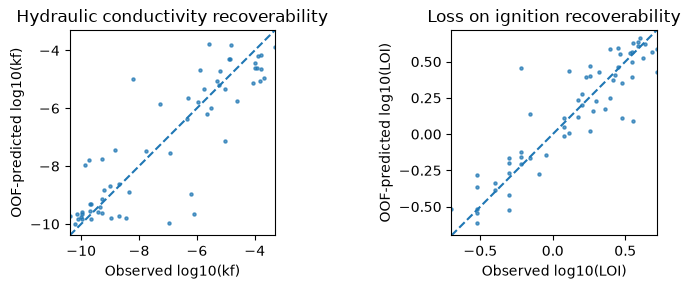

In [167]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))

titles = {
    "hyd_cond_kf_m_s": "Hydraulic conductivity recoverability",
    "loss_on_ignition_pct": "Loss on ignition recoverability"
}

labels = {
    "hyd_cond_kf_m_s": "kf",
    "loss_on_ignition_pct": "LOI"
}

for ax, target_col in zip(axes, TARGET_COLS):

    y_true = results[target_col]["y_log"]
    y_pred = results[target_col]["oof_log"]

    ax.scatter(y_true, y_pred, alpha=0.7, s=5)

    lower = min(y_true.min(), y_pred.min())
    upper = max(y_true.max(), y_pred.max())

    ax.plot([lower, upper], [lower, upper], linestyle="--")

    label = labels[target_col]
    ax.set_xlabel(f"Observed log10({label})")
    ax.set_ylabel(f"OOF-predicted log10({label})")
    ax.set_title(titles[target_col])

    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.show()

### Imputing

In [168]:
# # WITHOUT MICE (XGBOOST)

# def impute_feature(input_df, target_col, predictors, log_transform=False, model=None,):
#     """
#     Impute missing values of one feature using XGBoost.

#     Parameters
#     ----------
#     df : DataFrame
#     target_col : str
#         Column to impute.
#     predictors : list[str]
#         Predictor columns.
#     log_transform : bool
#         Whether to predict log10(target).
#     model : estimator or None
#     """

#     if model is None:
#         model = XGBRegressor(
#             objective="reg:squarederror",
#             n_estimators=400,
#             learning_rate=0.03,
#             max_depth=3,
#             min_child_weight=3,
#             subsample=0.8,
#             colsample_bytree=0.8,
#             reg_alpha=0.0,
#             reg_lambda=1.0,
#             random_state=42,
#             n_jobs=-1,
#         )

#     output_df = input_df.copy()

#     observed_mask = (output_df[target_col].notna() & np.isfinite(output_df[target_col]) & (output_df[target_col] > 0))
#     missing_mask = output_df[target_col].isna()

#     # Don't accidentally use the target itself
#     predictor_columns = [
#         col for col in predictors
#         if col != target_col
#     ]

#     X_train = output_df.loc[
#         observed_mask,
#         predictor_columns,
#     ]

#     if log_transform:
#         y_train = np.log10(output_df.loc[observed_mask, target_col].astype(float))
#     else:
#         y_train = output_df.loc[observed_mask, target_col].astype(float)

#     model.fit(X_train, y_train)

#     completed_column = f"{target_col}_completed"
#     missing_indicator = f"{target_col}_was_missing"

#     output_df[completed_column] = output_df[target_col]
#     output_df[missing_indicator] = missing_mask.astype(int)

#     if missing_mask.any():
#         X_missing = output_df.loc[ missing_mask, predictor_columns]
#         predictions = model.predict(X_missing)

#         if log_transform:
#             predictions = 10 ** predictions

#         output_df.loc[missing_mask, completed_column] = predictions

#     if log_transform:
#         output_df[f"log10_{completed_column}"] = np.log10(output_df[completed_column])

#     return output_df

In [176]:
def impute_features(input_df, impute_cols, predictors=None, log_transform_cols=None, applicable_mask=None, estimator=None, max_iter=20, random_state=42):
    """
    Impute multiple missing features jointly using MICE.
    """

    output_df = input_df.copy()

    if predictors is None:
        predictors = []

    if log_transform_cols is None:
        log_transform_cols = []

    if estimator is None:
        estimator = BayesianRidge()

    # Remove duplicates while preserving order
    mice_columns = list(dict.fromkeys(impute_cols + predictors))

    missing_columns = [col for col in mice_columns if col not in output_df.columns]

    if missing_columns:
        raise KeyError(f"These columns are not in the dataframe: {missing_columns}")

    if applicable_mask is None:
        applicable_mask = pd.Series(True, index=output_df.index,)
    else:
        applicable_mask = pd.Series(applicable_mask, index=output_df.index,).astype(bool)

    # Work only on rows where these variables are applicable
    mice_data = output_df.loc[applicable_mask, mice_columns].copy()

    # Ensure numeric input
    mice_data = mice_data.apply(pd.to_numeric,errors="coerce")

    # Store original missingness before transformations
    original_missing = {col: output_df[col].isna()for col in impute_cols}

    # Apply log10 transformation where requested
    transformed_column_names = {}

    for col in log_transform_cols:
        if col not in mice_columns:
            raise ValueError(
                f"{col!r} is in log_transform_cols but not in "
                "impute_cols or predictors."
            )

        transformed_name = f"__log10_{col}"
        transformed_column_names[col] = transformed_name

        values = mice_data[col].astype(float)

        # Non-positive values are invalid for log10
        valid_positive = values > 0

        mice_data[transformed_name] = np.nan
        mice_data.loc[valid_positive, transformed_name] = np.log10(values.loc[valid_positive])

        mice_data = mice_data.drop(columns=col)

    # Names actually passed into IterativeImputer
    model_columns = mice_data.columns.tolist()

    imputer = IterativeImputer(
        estimator=estimator,
        max_iter=max_iter,
        tol=1e-3,
        initial_strategy="median",
        imputation_order="ascending",
        skip_complete=True,
        sample_posterior=False,
        random_state=random_state,
    )

    imputed_array = imputer.fit_transform(mice_data)
    imputed_data = pd.DataFrame(imputed_array, index=mice_data.index, columns=model_columns)

    # Convert log-transformed variables back to their original scale
    for original_col, transformed_col in transformed_column_names.items():
        imputed_data[original_col] = (10 ** imputed_data[transformed_col])

    # Create completed columns and missing indicators
    # Create or update completed columns and missing indicators
    for col in impute_cols:
        completed_col = f"{col}_completed"
        missing_indicator = f"{col}_was_missing"

        # Create these only on the first call.
        # If they already exist, preserve previous imputations.
        if completed_col not in output_df.columns:
            output_df[completed_col] = output_df[col].copy()

        if missing_indicator not in output_df.columns:
            output_df[missing_indicator] = (
                output_df[col].isna().astype(int)
            )

        # Fill only originally missing values inside the current subset
        fill_mask = (
            applicable_mask
            & output_df[col].isna()
        )

        output_df.loc[
            fill_mask,
            completed_col,
        ] = imputed_data.loc[
            fill_mask,
            col,
        ]

        # Recalculate the log-completed column using all currently completed values
        if col in log_transform_cols:
            log_completed_col = f"log10_{completed_col}"

            output_df[log_completed_col] = np.nan

            positive_mask = (
                output_df[completed_col].notna()
                & np.isfinite(output_df[completed_col])
                & (output_df[completed_col] > 0)
            )

            output_df.loc[
                positive_mask,
                log_completed_col,
            ] = np.log10(
                output_df.loc[
                    positive_mask,
                    completed_col,
                ]
            )

    return output_df, imputer

In [177]:
mice_predictors = ['psd_size_at_d10_mm', 'psd_size_at_d20_mm', 'psd_size_at_d30_mm',
       'psd_size_at_d40_mm', 'psd_size_at_d50_mm', 'psd_size_at_d60_mm',
       'psd_size_at_d70_mm', 'psd_size_at_d80_mm', 'psd_size_at_d90_mm',
       'psd_size_at_d95_mm', 'psd_size_at_d98_mm', 'psd_has_sedimentation',
       'psd_passing_at_0_002mm_pct', 'psd_passing_at_0_063mm_pct',
       'psd_passing_at_2mm_pct', 'proctor_diam_mm', 'grain_density_g_cm3',
       'clay', 'silt', 'sand', 'gravel', 'feat_cu', 'feat_cc', 'feat_log_cu']

fine_mask = df["fine-grained"].astype(bool)
coarse_mask = ~fine_mask

fine_targets = [
    "atterberg_liquid_limit_pct",
    "atterberg_plastic_limit_pct",
    "loss_on_ignition_pct",
    "hyd_cond_kf_m_s",
]

df_impute, fine_mice_model = impute_features(
    input_df=df,
    impute_cols=fine_targets,
    predictors=mice_predictors,
    log_transform_cols=["hyd_cond_kf_m_s"],
    applicable_mask=fine_mask,
    random_state=42,
)

coarse_targets = [
    "loss_on_ignition_pct",
    "hyd_cond_kf_m_s",
]

df_impute, coarse_mice_model = impute_features(
    input_df=df_impute,
    impute_cols=coarse_targets,
    predictors=mice_predictors,
    log_transform_cols=["hyd_cond_kf_m_s"],
    applicable_mask=coarse_mask,
    random_state=42,
)

## Outlier Diagnosis

Leverage and Cook's distance for every training row, from an OLS fit of OWC on the final pipeline's 28-column imputed feature set (`IMPUTED_FEATURES`, MICE with the fine/coarse split, n = 201). This produces Fig. 1 of the paper (`Figures/owc_leverage_cooksd_id155.png`) and the values quoted in Section 2.3; id 155 is the basis for excluding that row from model1i's training set.

In [ ]:
from src.general_model_impute import IMPUTED_FEATURES, add_imputed_features, add_no_missing_features

OUTLIER_ID = 155

infl_df = add_no_missing_features(pd.read_csv('../data/train.csv'))
infl_df, _, _ = add_imputed_features(infl_df)

X_infl = np.column_stack([np.ones(len(infl_df)), infl_df[IMPUTED_FEATURES].astype(float).values])
y_infl = infl_df['proctor_owc_pct'].values
H = X_infl @ np.linalg.pinv(X_infl.T @ X_infl) @ X_infl.T
leverage = np.diag(H)
resid = y_infl - H @ y_infl
p_rank = np.linalg.matrix_rank(X_infl)
s2 = resid @ resid / (len(y_infl) - p_rank)
cooks_d = resid**2 / (p_rank * s2) * leverage / (1 - leverage) ** 2

is_out = (infl_df['id'] == OUTLIER_ID).values
next_d = cooks_d[~is_out].max()
print(f"n={len(infl_df)}, features={len(IMPUTED_FEATURES)}")
print(f"id {OUTLIER_ID}: leverage={leverage[is_out][0]:.3f}, Cook's D={cooks_d[is_out][0]:.1f}, next-highest={next_d:.2f}")

fig, ax = plt.subplots(figsize=(5.5, 4.4), dpi=200)
ax.scatter(leverage[~is_out], cooks_d[~is_out], facecolors='white', edgecolors='black', s=28,
           label=f"Other training samples ($n={(~is_out).sum()}$)")
ax.scatter(leverage[is_out], cooks_d[is_out], marker='^', color='black', s=160, label=f"id {OUTLIER_ID}")
ax.annotate(f"id {OUTLIER_ID}\nleverage = {leverage[is_out][0]:.3f}\nCook's D = {cooks_d[is_out][0]:.1f}\n"
            f"(next-highest: {next_d:.2f})",
            xy=(leverage[is_out][0], cooks_d[is_out][0]), xytext=(0.45, 0.4), fontweight='bold', fontsize=9,
            arrowprops=dict(arrowstyle='->', color='black'))
ax.set_yscale('symlog', linthresh=1e-2)
ax.set_xlim(0, 1.08)
ax.set_xlabel('Leverage $h_{ii}$')
ax.set_ylabel("Cook's distance (symlog scale)")
ax.set_title('Influence diagnostics, OWC OLS fit', fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='upper left', frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig('../Figures/owc_leverage_cooksd_id155.png')
plt.show()

## General Model Architecture Testing

### Constrained optimized blend of Ridge, GPR, and XGBoost.
Conclusion: Blend works better than residual correction

In [ ]:
def find_weights(P, y_true, model_names=None):
    P = np.asarray(P, dtype=float)
    y = np.asarray(y_true, dtype=float)

    if P.ndim != 2:
        raise ValueError(
            "P must be a 2D array with shape "
            "(n_samples, n_models)."
        )

    if len(y) != P.shape[0]:
        raise ValueError(
            f"P has {P.shape[0]} rows, "
            f"but y_true has {len(y)} values."
        )

    if not np.isfinite(P).all() or not np.isfinite(y).all():
        raise ValueError(
            "P and y_true must contain only finite values."
        )

    n_models = P.shape[1]

    if model_names is None:
        model_names = [
            f"model_{i}"
            for i in range(n_models)
        ]

    if len(model_names) != n_models:
        raise ValueError("model_names must match the number of columns in P.")

    # Use SSE rather than MSE so the optimization
    # objective is not unnecessarily tiny.
    def objective(weights):
        residuals = y - P @ weights
        return np.sum(residuals ** 2)

    result = minimize(
        objective,
        x0=np.full(n_models, 1 / n_models),
        method="SLSQP",
        bounds=[(0.0, 1.0)] * n_models,
        constraints={
            "type": "eq",
            "fun": lambda weights: np.sum(weights) - 1.0,
        },
        options={
            "ftol": 1e-12,
            "maxiter": 5000,
            "disp": False,
        },
    )

    if not result.success:
        print(
            f"Warning: optimizer failed ({result.message}). "
            "Using the best individual model."
        )

        mse = np.mean((P - y[:, None]) ** 2, axis=0)

        best = np.argmin(mse)

        weights = np.zeros(n_models)
        weights[best] = 1.0

    else:
        weights = result.x

    # Remove insignificant numerical noise and renormalize.
    weights[np.abs(weights) < 1e-10] = 0.0
    weights /= weights.sum()

    ensemble_oof = P @ weights

    print("Weights:")
    for name, weight in zip(model_names, weights):
        print(f"  {name}: {weight:.6f}")

    print(f"Iterations: {result.nit}")
    print(f"OOF R²: {r2_score(y, ensemble_oof):.4f}")
    print(
        "OOF RMSE: "
        f"{mean_squared_error(y, ensemble_oof) ** 0.5:.4f}"
    )

    return weights, ensemble_oof

#### Ridge + GPR + XGBoost

In [186]:
P_mdd = np.column_stack([
    ridge_mdd_oof,
    gpr_mdd_oof,
    xgb_mdd_oof,
])

P_owc = np.column_stack([
    ridge_owc_oof,
    gpr_owc_oof,
    xgb_owc_oof,
])

y_mdd_true = df["proctor_mdd_g_cm3"]
y_owc_true = df["proctor_owc_pct"]

model_names = ["ridge", "gpr", "xgboost"]

mdd_weights, mdd_ensemble_oof = find_weights(P_mdd, y_mdd_true, model_names=model_names)
owc_weights, owc_ensemble_oof = find_weights(P_owc, y_owc_true, model_names=model_names)

Weights:
  ridge: 0.110406
  gpr: 0.283509
  xgboost: 0.606085
Iterations: 8
OOF R²: 0.8508
OOF RMSE: 0.0540
Weights:
  ridge: 0.000000
  gpr: 0.272550
  xgboost: 0.727450
Iterations: 4
OOF R²: 0.8046
OOF RMSE: 1.4837


#### GPR + XGBoost

In [187]:
P_mdd_gpr_xgb = np.column_stack([gpr_mdd_oof,xgb_mdd_oof])
mdd_weights_2, mdd_ensemble_oof_2 = find_weights(P_mdd_gpr_xgb,y_mdd_true,model_names=["gpr", "xgboost"])
P_owc_gpr_xgb = np.column_stack([gpr_owc_oof,xgb_owc_oof])
owc_weights_2, owc_ensemble_oof_2 = find_weights(P_owc_gpr_xgb,y_owc_true,model_names=["gpr", "xgboost"])


Weights:
  gpr: 0.356345
  xgboost: 0.643655
Iterations: 3
OOF R²: 0.8492
OOF RMSE: 0.0543
Weights:
  gpr: 0.272550
  xgboost: 0.727450
Iterations: 2
OOF R²: 0.8046
OOF RMSE: 1.4837


#### Three blend with Imputations

### Ridge + weighted GPR residual correction.
Outer validation prediction = Ridge prediction + alpha × GPR correction

    Outer training data
    │
    ├── Inner CV Ridge predictions
    │       └── residual labels = y − Ridge OOF
    │
    ├── Ridge fitted on all outer training data
    │       └── predicts outer validation target
    │
    └── GPR fitted on residual labels
            └── predicts outer validation correction

Conclusion: Blend works better than residual correction

In [60]:
def ridge_gpr_residual_oof(X, y, ridge_pipeline, n_splits=5, random_state=42, alpha_bounds=(0.0, 2.0)):
    """
    Fit the hybrid model: hybrid prediction = Ridge prediction + alpha * GPR-predicted Ridge residual
    Returns: dict
        Contains alpha, OOF predictions, uncertainty, residuals,
        fold metrics, and overall metrics.
    """

    y_array = np.asarray(y, dtype=float).reshape(-1)
    n_samples = len(y_array)

    if len(X) != n_samples:
        raise ValueError(
            f"X contains {len(X)} rows, but y contains "
            f"{n_samples} values."
        )

    if not np.isfinite(y_array).all():
        raise ValueError("y contains NaN or infinite values.")

    X_is_pandas = isinstance(X, (pd.DataFrame, pd.Series))
    outer_cv = KFold(n_splits=n_splits, shuffle=True, random_state=random_state,)

    ridge_oof = np.full(n_samples, np.nan)
    residual_gpr_oof = np.full(n_samples, np.nan)
    residual_gpr_std_oof = np.full(n_samples, np.nan)

    fold_results = []

    for fold, (train_idx, valid_idx) in enumerate(outer_cv.split(X), start=1,):
        if X_is_pandas:
            X_train = X.iloc[train_idx]
            X_valid = X.iloc[valid_idx]
        else:
            X_array = np.asarray(X)
            X_train = X_array[train_idx]
            X_valid = X_array[valid_idx]

        y_train = y_array[train_idx]
        y_valid = y_array[valid_idx]

        # ---------------------------------------------------------
        # 1. Create leakage-free Ridge predictions on outer training
        #    rows using inner cross-validation
        # ---------------------------------------------------------
        inner_cv = KFold(n_splits=n_splits,shuffle=True,random_state=random_state + fold)
        ridge_train_oof = cross_val_predict(clone(ridge_pipeline),X_train,y_train,cv=inner_cv,method="predict")

        # These are the residual targets for GPR
        train_residuals = y_train - ridge_train_oof

        # ---------------------------------------------------------
        # 2. Fit Ridge on all outer-training rows and predict the
        #    outer validation rows
        # ---------------------------------------------------------
        ridge_outer = clone(ridge_pipeline)
        ridge_outer.fit(X_train, y_train)

        ridge_train_pred = ridge_outer.predict(X_train)
        ridge_valid_pred = ridge_outer.predict(X_valid)

        # ---------------------------------------------------------
        # 3. Scale X using only the outer training fold
        # ---------------------------------------------------------
        x_scaler = StandardScaler()

        X_train_scaled = x_scaler.fit_transform(X_train)
        X_valid_scaled = x_scaler.transform(X_valid)

        # ---------------------------------------------------------
        # 4. Scale residual targets using only outer training data
        # ---------------------------------------------------------
        residual_scaler = StandardScaler()
        train_residuals_scaled = residual_scaler.fit_transform(train_residuals.reshape(-1, 1)).ravel()

        # ---------------------------------------------------------
        # 5. Create and fit your custom GPR model
        # ---------------------------------------------------------
        residual_gpr = make_gpr_model(n_features=X_train_scaled.shape[1])
        residual_gpr.fit(X_train_scaled,train_residuals_scaled)

        # Training predictions are only used for diagnostics
        residual_train_pred_scaled = residual_gpr.predict(X_train_scaled)
        residual_valid_pred_scaled, residual_valid_std_scaled = (residual_gpr.predict(X_valid_scaled, return_std=True))

        # ---------------------------------------------------------
        # 6. Convert residual predictions to original target units
        # ---------------------------------------------------------
        residual_train_pred = residual_scaler.inverse_transform(residual_train_pred_scaled.reshape(-1, 1)).ravel()
        residual_valid_pred = residual_scaler.inverse_transform(residual_valid_pred_scaled.reshape(-1, 1)).ravel()

        # Standard deviation is rescaled by multiplying by target SD
        residual_valid_std = (residual_valid_std_scaled* residual_scaler.scale_[0])

        # ---------------------------------------------------------
        # 7. Save outer-fold OOF predictions
        # ---------------------------------------------------------
        ridge_oof[valid_idx] = ridge_valid_pred
        residual_gpr_oof[valid_idx] = residual_valid_pred
        residual_gpr_std_oof[valid_idx] = residual_valid_std

        # Full correction before alpha shrinkage, for diagnostics
        hybrid_train_unweighted = (ridge_train_pred + residual_train_pred)

        hybrid_valid_unweighted = (ridge_valid_pred + residual_valid_pred)

        fold_results.append({
            "Fold": f"Fold {fold}",
            "Ridge train R2": r2_score(y_train, ridge_train_pred),
            "Ridge val R2": r2_score(y_valid, ridge_valid_pred),
            "Ridge val RMSE": mean_squared_error(y_valid, ridge_valid_pred) ** 0.5,
            "Residual GPR train R2": r2_score(train_residuals, residual_train_pred),
            "Unweighted hybrid train R2": r2_score(y_train, hybrid_train_unweighted),
            "Unweighted hybrid val R2": r2_score(y_valid, hybrid_valid_unweighted),
            "Unweighted hybrid val RMSE": mean_squared_error(y_valid, hybrid_valid_unweighted) ** 0.5,
            "Mean residual prediction std": (residual_valid_std.mean())
        })

    # Confirm every row received an OOF prediction
    if np.isnan(ridge_oof).any():
        raise RuntimeError("Some Ridge OOF predictions were not generated.")

    if np.isnan(residual_gpr_oof).any():
        raise RuntimeError("Some GPR residual OOF predictions were not generated.")

    # -------------------------------------------------------------
    # 8. Optimize the GPR residual correction weight
    # -------------------------------------------------------------
    def objective(alpha):
        hybrid_prediction = (ridge_oof + alpha * residual_gpr_oof)
        return mean_squared_error(y_array, hybrid_prediction)

    optimization = minimize_scalar(objective,bounds=alpha_bounds,method="bounded")

    if not optimization.success:
        raise RuntimeError(
            f"Alpha optimization failed: "
            f"{optimization.message}"
        )

    alpha = float(optimization.x)

    hybrid_oof = (ridge_oof + alpha * residual_gpr_oof)

    # Actual errors after the complete hybrid prediction
    hybrid_residuals = y_array - hybrid_oof
    ridge_residuals = y_array - ridge_oof

    metrics = {
        "alpha": alpha,
        "ridge_r2": r2_score(y_array, ridge_oof),
        "ridge_rmse": mean_squared_error(y_array, ridge_oof) ** 0.5,
        "unweighted_hybrid_r2": r2_score(y_array, ridge_oof + residual_gpr_oof),
        "unweighted_hybrid_rmse": mean_squared_error(y_array, ridge_oof + residual_gpr_oof) ** 0.5,
        "weighted_hybrid_r2": r2_score(y_array, hybrid_oof),
        "weighted_hybrid_rmse": mean_squared_error(y_array, hybrid_oof) ** 0.5,
    }

    print(f"Residual correction weight alpha: {alpha:.4f}")
    print()
    print(f"Ridge OOF R²:       {metrics['ridge_r2']:.4f}")
    print(f"Ridge OOF RMSE:     {metrics['ridge_rmse']:.4f}")
    print()
    print(
        "Unweighted hybrid OOF R²:   "
        f"{metrics['unweighted_hybrid_r2']:.4f}"
    )
    print(
        "Unweighted hybrid OOF RMSE: "
        f"{metrics['unweighted_hybrid_rmse']:.4f}"
    )
    print()
    print(
        "Weighted hybrid OOF R²:     "
        f"{metrics['weighted_hybrid_r2']:.4f}"
    )
    print(
        "Weighted hybrid OOF RMSE:   "
        f"{metrics['weighted_hybrid_rmse']:.4f}"
    )

    return {
        "alpha": alpha,
        "ridge_oof": ridge_oof,
        "ridge_residuals": ridge_residuals,
        "residual_gpr_oof": residual_gpr_oof,
        "residual_gpr_std_oof": residual_gpr_std_oof,
        "hybrid_oof": hybrid_oof,
        "hybrid_residuals": hybrid_residuals,
        "fold_results": pd.DataFrame(fold_results),
        "metrics": metrics,
    }

In [61]:
mdd_result = ridge_gpr_residual_oof(X=X, y=y_mdd, ridge_pipeline=model3, n_splits=5, random_state=42)
owc_result = ridge_gpr_residual_oof(X=X, y=y_owc, ridge_pipeline=model4, n_splits=5, random_state=42)

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 4 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 6 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

...

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 5 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 6 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 4 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

Residual correction weight alpha: 0.6872

Ridge OOF R²:       0.2818
Ridge OOF RMSE:     2.8445

Unweighted hybrid OOF R²:   0.2977
Unweighted hybrid OOF RMSE: 2.8128

Weighted hybrid OOF R²:     0.3018
Weighted hybrid OOF RMSE:   2.8045


/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

### OWC/MDD Dependence
Conclusion: Independent model with 3-blend works the best

In [62]:
mdd_residual = (y_mdd_true.to_numpy() - mdd_ensemble_oof)
owc_residual = (y_owc_true.to_numpy() - owc_ensemble_oof)

residual_corr = np.corrcoef( mdd_residual, owc_residual)[0, 1]

print(f"Target correlation: {np.corrcoef(y_mdd_true, y_owc_true)[0, 1]:.4f}")
print(f"Residual correlation: {residual_corr:.4f}")

Target correlation: -0.7680
Residual correlation: -0.4735


In [63]:
FEATURE_COLUMNS = list(params_av)

MDD_COLUMN = "proctor_mdd_g_cm3"
OWC_COLUMN = "proctor_owc_pct"

required_columns = FEATURE_COLUMNS + [MDD_COLUMN, OWC_COLUMN]

model_df = (
    df[required_columns]
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=[MDD_COLUMN, OWC_COLUMN])
    .reset_index(drop=True)
)

X = model_df[FEATURE_COLUMNS].copy()

y_mdd = model_df[MDD_COLUMN].to_numpy(dtype=float)
y_owc = model_df[OWC_COLUMN].to_numpy(dtype=float)

print("X shape:", X.shape)
print("MDD shape:", y_mdd.shape)
print("OWC shape:", y_owc.shape)

def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    return {
        "r2": r2_score(y_true, y_pred),
        "rmse": mean_squared_error( y_true, y_pred) ** 0.5,
        "mae": mean_absolute_error( y_true, y_pred)
    }


def print_metrics(name, y_true, y_pred):
    metrics = regression_metrics(y_true, y_pred)

    print(f"\n{name}")
    print("-" * len(name))
    print(f"R²:   {metrics['r2']:.4f}")
    print(f"RMSE: {metrics['rmse']:.4f}")
    print(f"MAE:  {metrics['mae']:.4f}")

    return metrics

def make_xgb_model(random_state=42):
    return XGBRegressor(
        n_estimators=700,
        learning_rate=0.03,
        max_depth=4,
        min_child_weight=3,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.05,
        reg_lambda=1.0,
        objective="reg:squarederror",
        random_state=random_state,
        n_jobs=-1,
    )

def chained_regression_oof(X, y_first, y_second, first_model, second_model, outer_cv, inner_cv_splits=5, auxiliary_feature_name="predicted_first_target", random_state=42):
    """
    Leakage-safe chained regression.

    First stage:
        X -> y_first

    Second stage:
        [X, predicted y_first] -> y_second

    Parameters
    ----------
    X:
        pandas DataFrame or 2D numpy array.

    y_first:
        Target predicted by the first-stage model.

    y_second:
        Final target predicted by the chained model.

    first_model:
        sklearn-compatible regressor.

    second_model:
        sklearn-compatible regressor.

    outer_cv:
        Cross-validation splitter used for final evaluation.

    inner_cv_splits:
        Number of folds used to generate leakage-free first-stage
        predictions inside each outer-training fold.

    auxiliary_feature_name:
        Name of appended predicted-target feature.

    Returns
    -------
    results:
        Dictionary containing OOF predictions for both stages,
        fold IDs and metrics.
    """

    if isinstance(X, pd.DataFrame):
        X_df = X.reset_index(drop=True).copy()
    else:
        X_array = np.asarray(X, dtype=float)

        if X_array.ndim != 2:
            raise ValueError("X must be a 2D matrix.")

        X_df = pd.DataFrame(
            X_array,
            columns=[
                f"feature_{i}"
                for i in range(X_array.shape[1])
            ],
        )

    y_first = np.asarray(y_first, dtype=float)
    y_second = np.asarray(y_second, dtype=float)

    if len(X_df) != len(y_first) or len(X_df) != len(y_second):
        raise ValueError("X, y_first and y_second must have equal lengths.")

    n_samples = len(X_df)

    first_oof = np.full(n_samples, np.nan)
    second_oof = np.full(n_samples, np.nan)
    fold_ids = np.full(n_samples, -1, dtype=int)

    for fold_number, (train_idx, valid_idx) in enumerate(outer_cv.split(X_df)):
        print(f"Outer fold {fold_number + 1}")

        X_train = X_df.iloc[train_idx].copy()
        X_valid = X_df.iloc[valid_idx].copy()

        y_first_train = y_first[train_idx]
        y_second_train = y_second[train_idx]

        # Inner CV is used only inside the outer-training data.
        inner_cv = KFold(n_splits=inner_cv_splits, shuffle=True, random_state=random_state + fold_number)

        # Leakage-free first-stage predictions for outer-training rows.
        first_train_oof = cross_val_predict(
            clone(first_model),
            X_train,
            y_first_train,
            cv=inner_cv,
            method="predict",
            n_jobs=None,
        )

        # Fit first-stage model on all outer-training rows.
        first_model_fold = clone(first_model)
        first_model_fold.fit(X_train, y_first_train)

        # Predict auxiliary target for outer-validation rows.
        first_valid_pred = first_model_fold.predict(X_valid)

        # Add predicted target as a feature.
        X_train_chain = X_train.copy()
        X_valid_chain = X_valid.copy()

        X_train_chain[auxiliary_feature_name] = (first_train_oof)
        X_valid_chain[auxiliary_feature_name] = (first_valid_pred)

        second_model_fold = clone(second_model)
        second_model_fold.fit(X_train_chain, y_second_train)
        second_valid_pred = second_model_fold.predict(X_valid_chain)

        first_oof[valid_idx] = first_valid_pred
        second_oof[valid_idx] = second_valid_pred
        fold_ids[valid_idx] = fold_number

    if np.isnan(first_oof).any():
        raise RuntimeError("Some first-stage OOF predictions were not generated.")

    if np.isnan(second_oof).any():
        raise RuntimeError("Some second-stage OOF predictions were not generated.")

    return {
        "first_oof": first_oof,
        "second_oof": second_oof,
        "fold_ids": fold_ids,
        "first_metrics": regression_metrics(y_first, first_oof,),
        "second_metrics": regression_metrics(y_second, second_oof,),
    }

X shape: (201, 25)
MDD shape: (201,)
OWC shape: (201,)


In [64]:
outer_cv = KFold(n_splits=5, shuffle=True, random_state=42)

mdd_to_owc_results = chained_regression_oof(
    X=X,
    y_first=y_mdd,
    y_second=y_owc,
    first_model=make_xgb_model(random_state=101),
    second_model=make_xgb_model(random_state=102),
    outer_cv=outer_cv,
    inner_cv_splits=5,
    auxiliary_feature_name="predicted_mdd",
    random_state=42,
)

mdd_chain_oof = mdd_to_owc_results["first_oof"]
owc_from_mdd_chain_oof = mdd_to_owc_results["second_oof"]

print_metrics("First stage: MDD prediction", y_mdd, mdd_chain_oof)
print_metrics("Chained OWC prediction using predicted MDD", y_owc, owc_from_mdd_chain_oof)

outer_cv_reverse = KFold(n_splits=5, shuffle=True, random_state=42)

owc_to_mdd_results = chained_regression_oof(
    X=X,
    y_first=y_owc,
    y_second=y_mdd,
    first_model=make_xgb_model(random_state=201),
    second_model=make_xgb_model(random_state=202),
    outer_cv=outer_cv_reverse,
    inner_cv_splits=5,
    auxiliary_feature_name="predicted_owc",
    random_state=42,
)

owc_chain_oof = owc_to_mdd_results["first_oof"]
mdd_from_owc_chain_oof = owc_to_mdd_results["second_oof"]

print_metrics("First stage: OWC prediction", y_owc, owc_chain_oof)
print_metrics("Chained MDD prediction using predicted OWC", y_mdd, mdd_from_owc_chain_oof)

Outer fold 1


Outer fold 2


Outer fold 3


Outer fold 4


Outer fold 5


...

Outer fold 3


Outer fold 4


Outer fold 5



First stage: OWC prediction
---------------------------
R²:   0.7897
RMSE: 1.5393
MAE:  1.1633

Chained MDD prediction using predicted OWC
------------------------------------------
R²:   0.8303
RMSE: 0.0576
MAE:  0.0431


{'r2': 0.8303250875143005,
 'rmse': 0.05764220992940472,
 'mae': 0.04307859046423614}

In [65]:
def independent_xgb_oof(X, y, cv, random_state=42):
    model = make_xgb_model(random_state=random_state)

    predictions = cross_val_predict(model, X, y, cv=cv, method="predict", n_jobs=None)

    return predictions

baseline_cv_mdd = KFold(n_splits=5, shuffle=True, random_state=42)
baseline_cv_owc = KFold(n_splits=5, shuffle=True, random_state=42)
mdd_independent_oof = independent_xgb_oof(X, y_mdd, cv=baseline_cv_mdd, random_state=301)
owc_independent_oof = independent_xgb_oof(X, y_owc, cv=baseline_cv_owc, random_state=302)
print_metrics("Independent XGBoost: MDD", y_mdd, mdd_independent_oof)
print_metrics("Independent XGBoost: OWC", y_owc, owc_independent_oof)


Independent XGBoost: MDD
------------------------
R²:   0.8274
RMSE: 0.0581
MAE:  0.0434

Independent XGBoost: OWC
------------------------
R²:   0.7885
RMSE: 1.5436
MAE:  1.1667


{'r2': 0.7884812066546449,
 'rmse': 1.5436363176648724,
 'mae': 1.1666524554010647}

In [66]:
comparison_chain = pd.DataFrame({
    "architecture": ["Independent XGBoost", "OWC -> MDD chain", "Independent XGBoost", "MDD -> OWC chain"],
    "target": ["MDD", "MDD", "OWC", "OWC"],
    "r2": [
        r2_score(y_mdd, mdd_independent_oof),
        r2_score(y_mdd, mdd_from_owc_chain_oof),
        r2_score(y_owc, owc_independent_oof),
        r2_score(y_owc, owc_from_mdd_chain_oof),
    ],
    "rmse": [
        mean_squared_error(y_mdd, mdd_independent_oof) ** 0.5,
        mean_squared_error(y_mdd, mdd_from_owc_chain_oof) ** 0.5,
        mean_squared_error(y_owc, owc_independent_oof) ** 0.5,
        mean_squared_error(y_owc, owc_from_mdd_chain_oof) ** 0.5,
    ],
})

print(comparison_chain)

          architecture target        r2      rmse
0  Independent XGBoost    MDD  0.827369  0.058142
1     OWC -> MDD chain    MDD  0.830325  0.057642
2  Independent XGBoost    OWC  0.788481  1.543636
3     MDD -> OWC chain    OWC  0.787395  1.547595


In [67]:
Y = np.column_stack([y_mdd, y_owc])

def shared_mlp_multioutput_oof(X, y_mdd, y_owc, outer_cv, hidden_layer_sizes=(128, 64, 32), alpha=1e-3, learning_rate_init=1e-3, max_iter=2000, random_state=42):
    """
    Leakage-safe outer-CV evaluation of a shared multi-output MLP.

    The model has shared hidden layers and two outputs:
        output 0 = MDD
        output 1 = OWC

    Both X and Y are scaled separately inside every outer fold.
    """

    if isinstance(X, pd.DataFrame):
        X_array = X.to_numpy(dtype=float)
    else:
        X_array = np.asarray(X, dtype=float)

    y_mdd = np.asarray(y_mdd, dtype=float)
    y_owc = np.asarray(y_owc, dtype=float)

    Y = np.column_stack([ y_mdd, y_owc])

    n_samples = len(X_array)

    Y_oof = np.full(shape=(n_samples, 2), fill_value=np.nan, dtype=float)

    fold_ids = np.full(n_samples, -1, dtype=int)

    fold_histories = []

    for fold_number, (train_idx, valid_idx) in enumerate(outer_cv.split(X_array)):
        print(f"Shared MLP outer fold {fold_number + 1}")

        X_train = X_array[train_idx]
        X_valid = X_array[valid_idx]

        Y_train = Y[train_idx]

        # Input preprocessing fitted only on outer-training data.
        x_imputer = SimpleImputer(strategy="median")

        x_scaler = StandardScaler()
        y_scaler = StandardScaler()

        X_train_imputed = x_imputer.fit_transform(X_train)
        X_valid_imputed = x_imputer.transform(X_valid)
        X_train_scaled = x_scaler.fit_transform(X_train_imputed)
        X_valid_scaled = x_scaler.transform(X_valid_imputed)
        Y_train_scaled = y_scaler.fit_transform(Y_train)

        model = MLPRegressor(
            hidden_layer_sizes=hidden_layer_sizes,
            activation="relu",
            solver="adam",
            alpha=alpha,
            batch_size="auto",
            learning_rate="adaptive",
            learning_rate_init=learning_rate_init,
            max_iter=max_iter,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=50,
            random_state=random_state + fold_number,
        )

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model.fit(X_train_scaled, Y_train_scaled)

        Y_valid_scaled_pred = model.predict(X_valid_scaled)

        # Ensure shape is always (n_validation, 2).
        Y_valid_scaled_pred = np.asarray(Y_valid_scaled_pred, dtype=float).reshape(-1, 2)

        Y_valid_pred = y_scaler.inverse_transform(Y_valid_scaled_pred)

        Y_oof[valid_idx] = Y_valid_pred
        fold_ids[valid_idx] = fold_number

        fold_histories.append({ "fold": fold_number, "n_iterations": model.n_iter_, "final_loss": model.loss_})

    if np.isnan(Y_oof).any():
        raise RuntimeError("Some shared-network OOF predictions are missing.")

    mdd_oof = Y_oof[:, 0]
    owc_oof = Y_oof[:, 1]

    return {
        "mdd_oof": mdd_oof,
        "owc_oof": owc_oof,
        "joint_oof": Y_oof,
        "fold_ids": fold_ids,
        "fold_histories": pd.DataFrame(
            fold_histories
        ),
        "mdd_metrics": regression_metrics(
            y_mdd,
            mdd_oof,
        ),
        "owc_metrics": regression_metrics(
            y_owc,
            owc_oof,
        ),
    }

shared_cv = KFold(n_splits=5, shuffle=True, random_state=42)

shared_results = shared_mlp_multioutput_oof(
    X=X,
    y_mdd=y_mdd,
    y_owc=y_owc,
    outer_cv=shared_cv,
    hidden_layer_sizes=(128, 64, 32),
    alpha=1e-3,
    learning_rate_init=5e-4,
    max_iter=2500,
    random_state=42,
)

shared_mdd_oof = shared_results["mdd_oof"]
shared_owc_oof = shared_results["owc_oof"]

print_metrics("Shared multi-output MLP: MDD", y_mdd, shared_mdd_oof)
print_metrics("Shared multi-output MLP: OWC", y_owc, shared_owc_oof)

print(shared_results["fold_histories"])

Shared MLP outer fold 1
Shared MLP outer fold 2
Shared MLP outer fold 3
Shared MLP outer fold 4


Shared MLP outer fold 5

Shared multi-output MLP: MDD
----------------------------
R²:   0.0970
RMSE: 0.1330
MAE:  0.0545

Shared multi-output MLP: OWC
----------------------------
R²:   -0.1509
RMSE: 3.6008
MAE:  1.4220
   fold  n_iterations  final_loss
0     0           167    0.027874
1     1           104    0.045407
2     2           102    0.039204
3     3           255    0.021872
4     4           159    0.044524


In [68]:
def separate_mlp_oof(X, y, outer_cv, hidden_layer_sizes=(128, 64, 32), alpha=1e-3, learning_rate_init=1e-3, max_iter=2000, random_state=42):
    if isinstance(X, pd.DataFrame):
        X_array = X.to_numpy(dtype=float)
    else:
        X_array = np.asarray(X, dtype=float)

    y = np.asarray(y, dtype=float)

    predictions = np.full(len(y), np.nan, dtype=float,)

    for fold_number, (train_idx, valid_idx) in enumerate(outer_cv.split(X_array)):
        X_train = X_array[train_idx]
        X_valid = X_array[valid_idx]
        y_train = y[train_idx].reshape(-1, 1)

        x_imputer = SimpleImputer(strategy="median")

        x_scaler = StandardScaler()
        y_scaler = StandardScaler()

        X_train_imputed = x_imputer.fit_transform(X_train)
        X_valid_imputed = x_imputer.transform(X_valid)
        X_train_scaled = x_scaler.fit_transform(X_train_imputed)
        X_valid_scaled = x_scaler.transform(X_valid_imputed)
        y_train_scaled = (y_scaler.fit_transform(y_train).ravel())

        model = MLPRegressor(
            hidden_layer_sizes=hidden_layer_sizes,
            activation="relu",
            solver="adam",
            alpha=alpha,
            learning_rate="adaptive",
            learning_rate_init=learning_rate_init,
            max_iter=max_iter,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=50,
            random_state=random_state + fold_number,
        )

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")

            model.fit(X_train_scaled, y_train_scaled)

        valid_scaled_pred = model.predict(X_valid_scaled).reshape(-1, 1)

        valid_pred = (y_scaler.inverse_transform(valid_scaled_pred).ravel())

        predictions[valid_idx] = valid_pred

    if np.isnan(predictions).any():
        raise RuntimeError("Some separate-MLP OOF predictions are missing.")

    return predictions

separate_mdd_cv = KFold(n_splits=5, shuffle=True, random_state=42)

separate_owc_cv = KFold(n_splits=5, shuffle=True, random_state=42)

separate_mlp_mdd_oof = separate_mlp_oof(
    X=X,
    y=y_mdd,
    outer_cv=separate_mdd_cv,
    hidden_layer_sizes=(128, 64, 32),
    alpha=1e-3,
    learning_rate_init=5e-4,
    max_iter=2500,
    random_state=501,
)

separate_mlp_owc_oof = separate_mlp_oof(
    X=X,
    y=y_owc,
    outer_cv=separate_owc_cv,
    hidden_layer_sizes=(128, 64, 32),
    alpha=1e-3,
    learning_rate_init=5e-4,
    max_iter=2500,
    random_state=601,
)

print_metrics("Separate MLP: MDD", y_mdd, separate_mlp_mdd_oof,)
print_metrics("Separate MLP: OWC", y_owc, separate_mlp_owc_oof,)


Separate MLP: MDD
-----------------
R²:   0.1786
RMSE: 0.1268
MAE:  0.0531

Separate MLP: OWC
-----------------
R²:   0.7092
RMSE: 1.8101
MAE:  1.2176


{'r2': 0.7091560392731558,
 'rmse': 1.8100915159225477,
 'mae': 1.2176156217559275}

In [69]:
def result_row(architecture, target, y_true, y_pred,):
    metrics = regression_metrics(y_true, y_pred)

    return {
        "architecture": architecture,
        "target": target,
        "r2": metrics["r2"],
        "rmse": metrics["rmse"],
        "mae": metrics["mae"],
    }

comparison_rows = [
    result_row("Independent XGBoost", "MDD", y_mdd, mdd_independent_oof),
    result_row("Independent XGBoost", "OWC", y_owc, owc_independent_oof),
    result_row("OWC -> MDD chain", "MDD", y_mdd, mdd_from_owc_chain_oof),
    result_row("MDD -> OWC chain", "OWC", y_owc, owc_from_mdd_chain_oof),
    result_row("Separate MLP", "MDD", y_mdd, separate_mlp_mdd_oof),
    result_row("Separate MLP", "OWC", y_owc, separate_mlp_owc_oof),
    result_row("Shared multi-output MLP", "MDD", y_mdd, shared_mdd_oof),
    result_row("Shared multi-output MLP", "OWC", y_owc, shared_owc_oof),
]

comparison_rows.extend([
    result_row("Separate Ridge + GPR + XGBoost blend", "MDD", y_mdd, mdd_ensemble_oof),
    result_row("Separate Ridge + GPR + XGBoost blend", "OWC", y_owc, owc_ensemble_oof),
])

comparison_df = pd.DataFrame(comparison_rows)
comparison_df = comparison_df.sort_values(["target", "r2"], ascending=[True, False]).reset_index(drop=True)

print(comparison_df)

                           architecture target        r2      rmse       mae
0  Separate Ridge + GPR + XGBoost blend    MDD  0.850405  0.054124  0.040920
1                      OWC -> MDD chain    MDD  0.830325  0.057642  0.043079
2                   Independent XGBoost    MDD  0.827369  0.058142  0.043406
3                          Separate MLP    MDD  0.178618  0.126825  0.053072
4               Shared multi-output MLP    MDD  0.096968  0.132979  0.054503
5  Separate Ridge + GPR + XGBoost blend    OWC  0.804576  1.483747  1.127988
6                   Independent XGBoost    OWC  0.788481  1.543636  1.166652
7                      MDD -> OWC chain    OWC  0.787395  1.547595  1.184857
8                          Separate MLP    OWC  0.709156  1.810092  1.217616
9               Shared multi-output MLP    OWC -0.150945  3.600791  1.421959


In [70]:
shared_mdd_residual = (y_mdd - shared_mdd_oof)
shared_owc_residual = (y_owc - shared_owc_oof)
shared_residual_corr = np.corrcoef(shared_mdd_residual, shared_owc_residual)[0, 1]

print("Shared MLP residual correlation:", f"{shared_residual_corr:.4f}")

Shared MLP residual correlation: -0.8884


### Three blend with imputed data

In [201]:
def generate_three_model_oof(
    input_df,
    feature_columns,
    target_column,
    n_splits=5,
    random_state=42,
):
    """
    Generate OOF predictions from the same Ridge, GPR and XGBoost
    models used in the notebook.
    """

    required_columns = list(feature_columns) + [target_column]

    model_df = (
        input_df[required_columns]
        .replace([np.inf, -np.inf], np.nan)
        .dropna(subset=required_columns)
        .copy()
    )

    X = model_df[feature_columns].copy()
    y = model_df[target_column].astype(float).copy()

    cv = KFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state,
    )

    # ============================================================
    # 1. RIDGE — same setup as notebook
    # ============================================================

    alphas = np.logspace(-4, 4, 100)

    ridge_model = make_pipeline(
        StandardScaler(),
        RidgeCV(
            alphas=alphas,
            cv=5,
        ),
    )

    ridge_oof = cross_val_predict(
        ridge_model,
        X,
        y,
        cv=cv,
        method="predict",
    )

    # ============================================================
    # 2. XGBOOST — same setup as notebook
    # ============================================================

    xgb_oof = np.full(len(X), np.nan)

    for train_idx, val_idx in cv.split(X):
        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]

        xgb_model = XGBRegressor(
            objective="reg:squarederror",
            n_estimators=300,
            learning_rate=0.03,
            max_depth=3,
            min_child_weight=3,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.0,
            reg_lambda=1.0,
            random_state=42,
            n_jobs=-1,
        )

        xgb_model.fit(
            X_train,
            y_train,
        )

        xgb_oof[val_idx] = xgb_model.predict(X_val)

    # ============================================================
    # 3. GPR — same setup as notebook
    # ============================================================

    gpr_oof = np.full(len(X), np.nan)

    for train_idx, val_idx in cv.split(X):
        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]

        # Scale inputs using training fold only
        x_scaler = StandardScaler()

        X_train_scaled = x_scaler.fit_transform(X_train)
        X_val_scaled = x_scaler.transform(X_val)

        # Scale target using training fold only
        y_scaler = StandardScaler()

        y_train_scaled = y_scaler.fit_transform(
            y_train.to_numpy().reshape(-1, 1)
        ).ravel()

        gpr_model = make_gpr_model(
            n_features=X_train_scaled.shape[1]
        )

        gpr_model.fit(
            X_train_scaled,
            y_train_scaled,
        )

        val_pred_scaled = gpr_model.predict(
            X_val_scaled
        )

        val_pred = y_scaler.inverse_transform(
            val_pred_scaled.reshape(-1, 1)
        ).ravel()

        gpr_oof[val_idx] = val_pred

    return {
        "index": model_df.index,
        "y_true": y.to_numpy(),
        "ridge_oof": ridge_oof,
        "gpr_oof": gpr_oof,
        "xgb_oof": xgb_oof,
    }

In [202]:
def evaluate_three_blend(input_df, feature_columns, target_column, experiment_name, n_splits=5, random_state=42):
    """
    Generate OOF predictions and optimize the same
    Ridge + GPR + XGBoost convex blend.
    """

    oof_results = generate_three_model_oof(
        input_df=input_df,
        feature_columns=feature_columns,
        target_column=target_column,
        n_splits=n_splits,
        random_state=random_state,
    )

    # prediction_matrix = np.column_stack([
    #     oof_results["ridge_oof"],
    #     oof_results["gpr_oof"],
    #     oof_results["xgb_oof"],
    # ])

    prediction_matrix = np.column_stack([
        oof_results["ridge_oof"],
        oof_results["gpr_oof"],
        oof_results["xgb_oof"],
    ])

    print("\n--- Debug ---")
    print("Prediction matrix shape:", prediction_matrix.shape)

    for i, name in enumerate(["ridge", "gpr", "xgboost"]):
        print(
            f"{name}:",
            "NaN =", np.isnan(prediction_matrix[:, i]).sum(),
            "Inf =", np.isinf(prediction_matrix[:, i]).sum(),
            "Std =", prediction_matrix[:, i].std(),
            "Min =", np.nanmin(prediction_matrix[:, i]),
            "Max =", np.nanmax(prediction_matrix[:, i]),
        )

    print("NaNs in y_true:", np.isnan(oof_results["y_true"]).sum())
    print("Inf in y_true:", np.isinf(oof_results["y_true"]).sum())
    print("----------------\n")

    model_names = ["ridge", "gpr", "xgboost"]
    weights, ensemble_oof = find_weights(P=prediction_matrix, y_true=oof_results["y_true"], model_names=model_names)

    y_true = oof_results["y_true"]

    result = {
        "experiment": experiment_name,
        "target": target_column,
        "n_samples": len(y_true),
        "n_features": len(feature_columns),
        "ridge_weight": weights[0],
        "gpr_weight": weights[1],
        "xgboost_weight": weights[2],
        "r2": r2_score(y_true, ensemble_oof),
        "rmse": mean_squared_error(y_true, ensemble_oof) ** 0.5,
        "mae": mean_absolute_error(y_true, ensemble_oof),
    }

    print(f"\n{experiment_name} — {target_column}")
    print("-" * 60)

    for model_name, weight in zip(model_names, weights):
        print(f"{model_name:10s}: {weight:.4f}")

    print(f"R²:   {result['r2']:.4f}")
    print(f"RMSE: {result['rmse']:.4f}")
    print(f"MAE:  {result['mae']:.4f}")

    return result, {
        **oof_results,
        "weights": weights,
        "ensemble_oof": ensemble_oof,
    }

In [203]:
features_universal = list(mice_predictors)

features_plus_kf = list(mice_predictors) + [
    "log10_hyd_cond_kf_m_s_completed",
    "hyd_cond_kf_m_s_was_missing",
]

features_plus_loi = list(mice_predictors) + [
    "loss_on_ignition_pct_completed",
    "loss_on_ignition_pct_was_missing",
]

features_plus_both = list(mice_predictors) + [
    "log10_hyd_cond_kf_m_s_completed",
    "hyd_cond_kf_m_s_was_missing",
    "loss_on_ignition_pct_completed",
    "loss_on_ignition_pct_was_missing",
]

feature_sets = {
    "Universal only": features_universal,
    "Universal + kf": features_plus_kf,
    "Universal + LOI": features_plus_loi,
    "Universal + kf + LOI": features_plus_both,
}


for name, columns in feature_sets.items():
    missing_columns = [
        column
        for column in columns
        if column not in df_impute.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{name} is missing columns: {missing_columns}"
        )

    print(
        name,
        "| features:",
        len(columns),
        "| missing values:",
        df_impute[columns].isna().sum().sum(),
    )

Universal only | features: 24 | missing values: 0
Universal + kf | features: 26 | missing values: 0
Universal + LOI | features: 26 | missing values: 0
Universal + kf + LOI | features: 28 | missing values: 0


In [204]:
MDD_COLUMN = "proctor_mdd_g_cm3"
OWC_COLUMN = "proctor_owc_pct"

all_results = []
all_oof_results = {}

for experiment_name, feature_columns in feature_sets.items():
    print("\n" + "=" * 75)
    print(experiment_name)
    print("=" * 75)

    mdd_result, mdd_oof = evaluate_three_blend(
        input_df=df_impute,
        feature_columns=feature_columns,
        target_column=MDD_COLUMN,
        experiment_name=experiment_name,
        n_splits=5,
        random_state=42,
    )

    owc_result, owc_oof = evaluate_three_blend(
        input_df=df_impute,
        feature_columns=feature_columns,
        target_column=OWC_COLUMN,
        experiment_name=experiment_name,
        n_splits=5,
        random_state=42,
    )

    all_results.extend([
        mdd_result,
        owc_result,
    ])

    all_oof_results[
        (experiment_name, "MDD")
    ] = mdd_oof

    all_oof_results[
        (experiment_name, "OWC")
    ] = owc_oof


Universal only


/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 4 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre


--- Debug ---
Prediction matrix shape: (201, 3)
ridge: NaN = 0 Inf = 0 Std = 0.11654215214640608 Min = 1.692732507756976 Max = 2.2135470517412457
gpr: NaN = 0 Inf = 0 Std = 0.12846969297263158 Min = 1.670905193828186 Max = 2.188370174579816
xgboost: NaN = 0 Inf = 0 Std = 0.1257964543382267 Min = 1.7004127502441406 Max = 2.1842429637908936
NaNs in y_true: 0
Inf in y_true: 0
----------------

Weights:
  ridge: 0.122136
  gpr: 0.287152
  xgboost: 0.590712
Iterations: 8
OOF R²: 0.8506
OOF RMSE: 0.0541

Universal only — proctor_mdd_g_cm3
------------------------------------------------------------
ridge     : 0.1221
gpr       : 0.2872
xgboost   : 0.5907
R²:   0.8506
RMSE: 0.0541
MAE:  0.0410


/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre


--- Debug ---
Prediction matrix shape: (201, 3)
ridge: NaN = 0 Inf = 0 Std = 3.3771936090824948 Min = -15.919019878935469 Max = 18.51085253902383
gpr: NaN = 0 Inf = 0 Std = 2.9911312458079573 Min = 5.788363130131081 Max = 19.41028740857007
xgboost: NaN = 0 Inf = 0 Std = 3.080091111830989 Min = 4.9804368019104 Max = 19.343673706054688
NaNs in y_true: 0
Inf in y_true: 0
----------------

Weights:
  ridge: 0.000000
  gpr: 0.000000
  xgboost: 1.000000
Iterations: 8
OOF R²: 0.8006
OOF RMSE: 1.4989

Universal only — proctor_owc_pct
------------------------------------------------------------
ridge     : 0.0000
gpr       : 0.0000
xgboost   : 1.0000
R²:   0.8006
RMSE: 1.4989
MAE:  1.1501

Universal + kf


...

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 4 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre


--- Debug ---
Prediction matrix shape: (201, 3)
ridge: NaN = 0 Inf = 0 Std = 0.11844195582576486 Min = 1.6842256382499157 Max = 2.200716658919162
gpr: NaN = 0 Inf = 0 Std = 0.1289739331558371 Min = 1.6594180473971312 Max = 2.1883242671019847
xgboost: NaN = 0 Inf = 0 Std = 0.12494803443082962 Min = 1.7066013813018799 Max = 2.183814764022827
NaNs in y_true: 0
Inf in y_true: 0
----------------

Weights:
  ridge: 0.151013
  gpr: 0.332048
  xgboost: 0.516939
Iterations: 8
OOF R²: 0.8619
OOF RMSE: 0.0520

Universal + kf + LOI — proctor_mdd_g_cm3
------------------------------------------------------------
ridge     : 0.1510
gpr       : 0.3320
xgboost   : 0.5169
R²:   0.8619
RMSE: 0.0520
MAE:  0.0402


/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre


--- Debug ---
Prediction matrix shape: (201, 3)
ridge: NaN = 0 Inf = 0 Std = 3.4288410884987326 Min = -16.99187291273298 Max = 18.533792714928744
gpr: NaN = 0 Inf = 0 Std = 2.9234892487174093 Min = 5.9373868465407 Max = 19.45797161186413
xgboost: NaN = 0 Inf = 0 Std = 3.052059379711962 Min = 5.417597770690918 Max = 19.547868728637695
NaNs in y_true: 0
Inf in y_true: 0
----------------

Weights:
  ridge: 0.000000
  gpr: 0.089389
  xgboost: 0.910611
Iterations: 10
OOF R²: 0.8048
OOF RMSE: 1.4829

Universal + kf + LOI — proctor_owc_pct
------------------------------------------------------------
ridge     : 0.0000
gpr       : 0.0894
xgboost   : 0.9106
R²:   0.8048
RMSE: 1.4829
MAE:  1.1434


/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

In [205]:
# Together

comparison_df = (
    pd.DataFrame(all_results)
    .sort_values(
        by=["target", "r2"],
        ascending=[True, False],
    )
    .reset_index(drop=True)
)

comparison_df

,experiment,target,n_samples,n_features,ridge_weight,gpr_weight,xgboost_weight,r2,rmse,mae
0,Universal + kf + LOI,proctor_mdd_g_cm3,201,28,0.151013,0.332048,0.516939,0.861881,0.052007,0.040199
1,Universal + LOI,proctor_mdd_g_cm3,201,26,0.061397,0.330865,0.607738,0.859387,0.052474,0.040036
2,Universal + kf,proctor_mdd_g_cm3,201,26,0.139983,0.335025,0.524992,0.854643,0.053352,0.041124
3,Universal only,proctor_mdd_g_cm3,201,24,0.122136,0.287152,0.590712,0.850643,0.054081,0.041002
4,Universal + LOI,proctor_owc_pct,201,26,0.000000,0.108596,0.891404,0.807851,1.471260,1.123474
5,Universal + kf + LOI,proctor_owc_pct,201,28,0.000000,0.089389,0.910611,0.804808,1.482863,1.143354
6,Universal + kf,proctor_owc_pct,201,26,0.000000,0.226607,0.773393,0.802688,1.490894,1.133605
7,Universal only,proctor_owc_pct,201,24,0.000000,0.000000,1.000000,0.800570,1.498876,1.150053


In [208]:
# Separate

comparison_df = (
    pd.DataFrame(all_results)
    .sort_values(
        by=["target", "r2"],
        ascending=[True, False],
    )
    .reset_index(drop=True)
)

comparison_df

,experiment,target,n_samples,n_features,ridge_weight,gpr_weight,xgboost_weight,r2,rmse,mae
0,Universal + kf + LOI,proctor_mdd_g_cm3,201,28,0.151013,0.332048,0.516939,0.861881,0.052007,0.040199
1,Universal + LOI,proctor_mdd_g_cm3,201,26,0.061397,0.330865,0.607738,0.859387,0.052474,0.040036
2,Universal + kf,proctor_mdd_g_cm3,201,26,0.139983,0.335025,0.524992,0.854643,0.053352,0.041124
3,Universal only,proctor_mdd_g_cm3,201,24,0.122136,0.287152,0.590712,0.850643,0.054081,0.041002
4,Universal + LOI,proctor_owc_pct,201,26,0.000000,0.108596,0.891404,0.807851,1.471260,1.123474
5,Universal + kf + LOI,proctor_owc_pct,201,28,0.000000,0.089389,0.910611,0.804808,1.482863,1.143354
6,Universal + kf,proctor_owc_pct,201,26,0.000000,0.226607,0.773393,0.802688,1.490894,1.133605
7,Universal only,proctor_owc_pct,201,24,0.000000,0.000000,1.000000,0.800570,1.498876,1.150053


In [207]:
from scipy.optimize import minimize

oof = all_oof_results[("Universal + LOI", "MDD")]

P = np.column_stack([
    oof["ridge_oof"],
    oof["gpr_oof"],
    oof["xgb_oof"],
])

y = oof["y_true"]

def objective(w):
    return np.mean((y - P @ w) ** 2)

res = minimize(
    objective,
    x0=[1/3, 1/3, 1/3],
    method="SLSQP",
    bounds=[(0, 1)] * 3,
    constraints={"type": "eq", "fun": lambda w: np.sum(w) - 1},
)

print(res)

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: 0.0027602550432457053
           x: [ 4.788e-02  4.076e-01  5.445e-01]
         nit: 6
         jac: [ 6.846e-03  6.982e-03  6.798e-03]
        nfev: 24
        njev: 6
 multipliers: [ 6.875e-03]


## Soil Specific: Fine- vs. Coarse- Grained

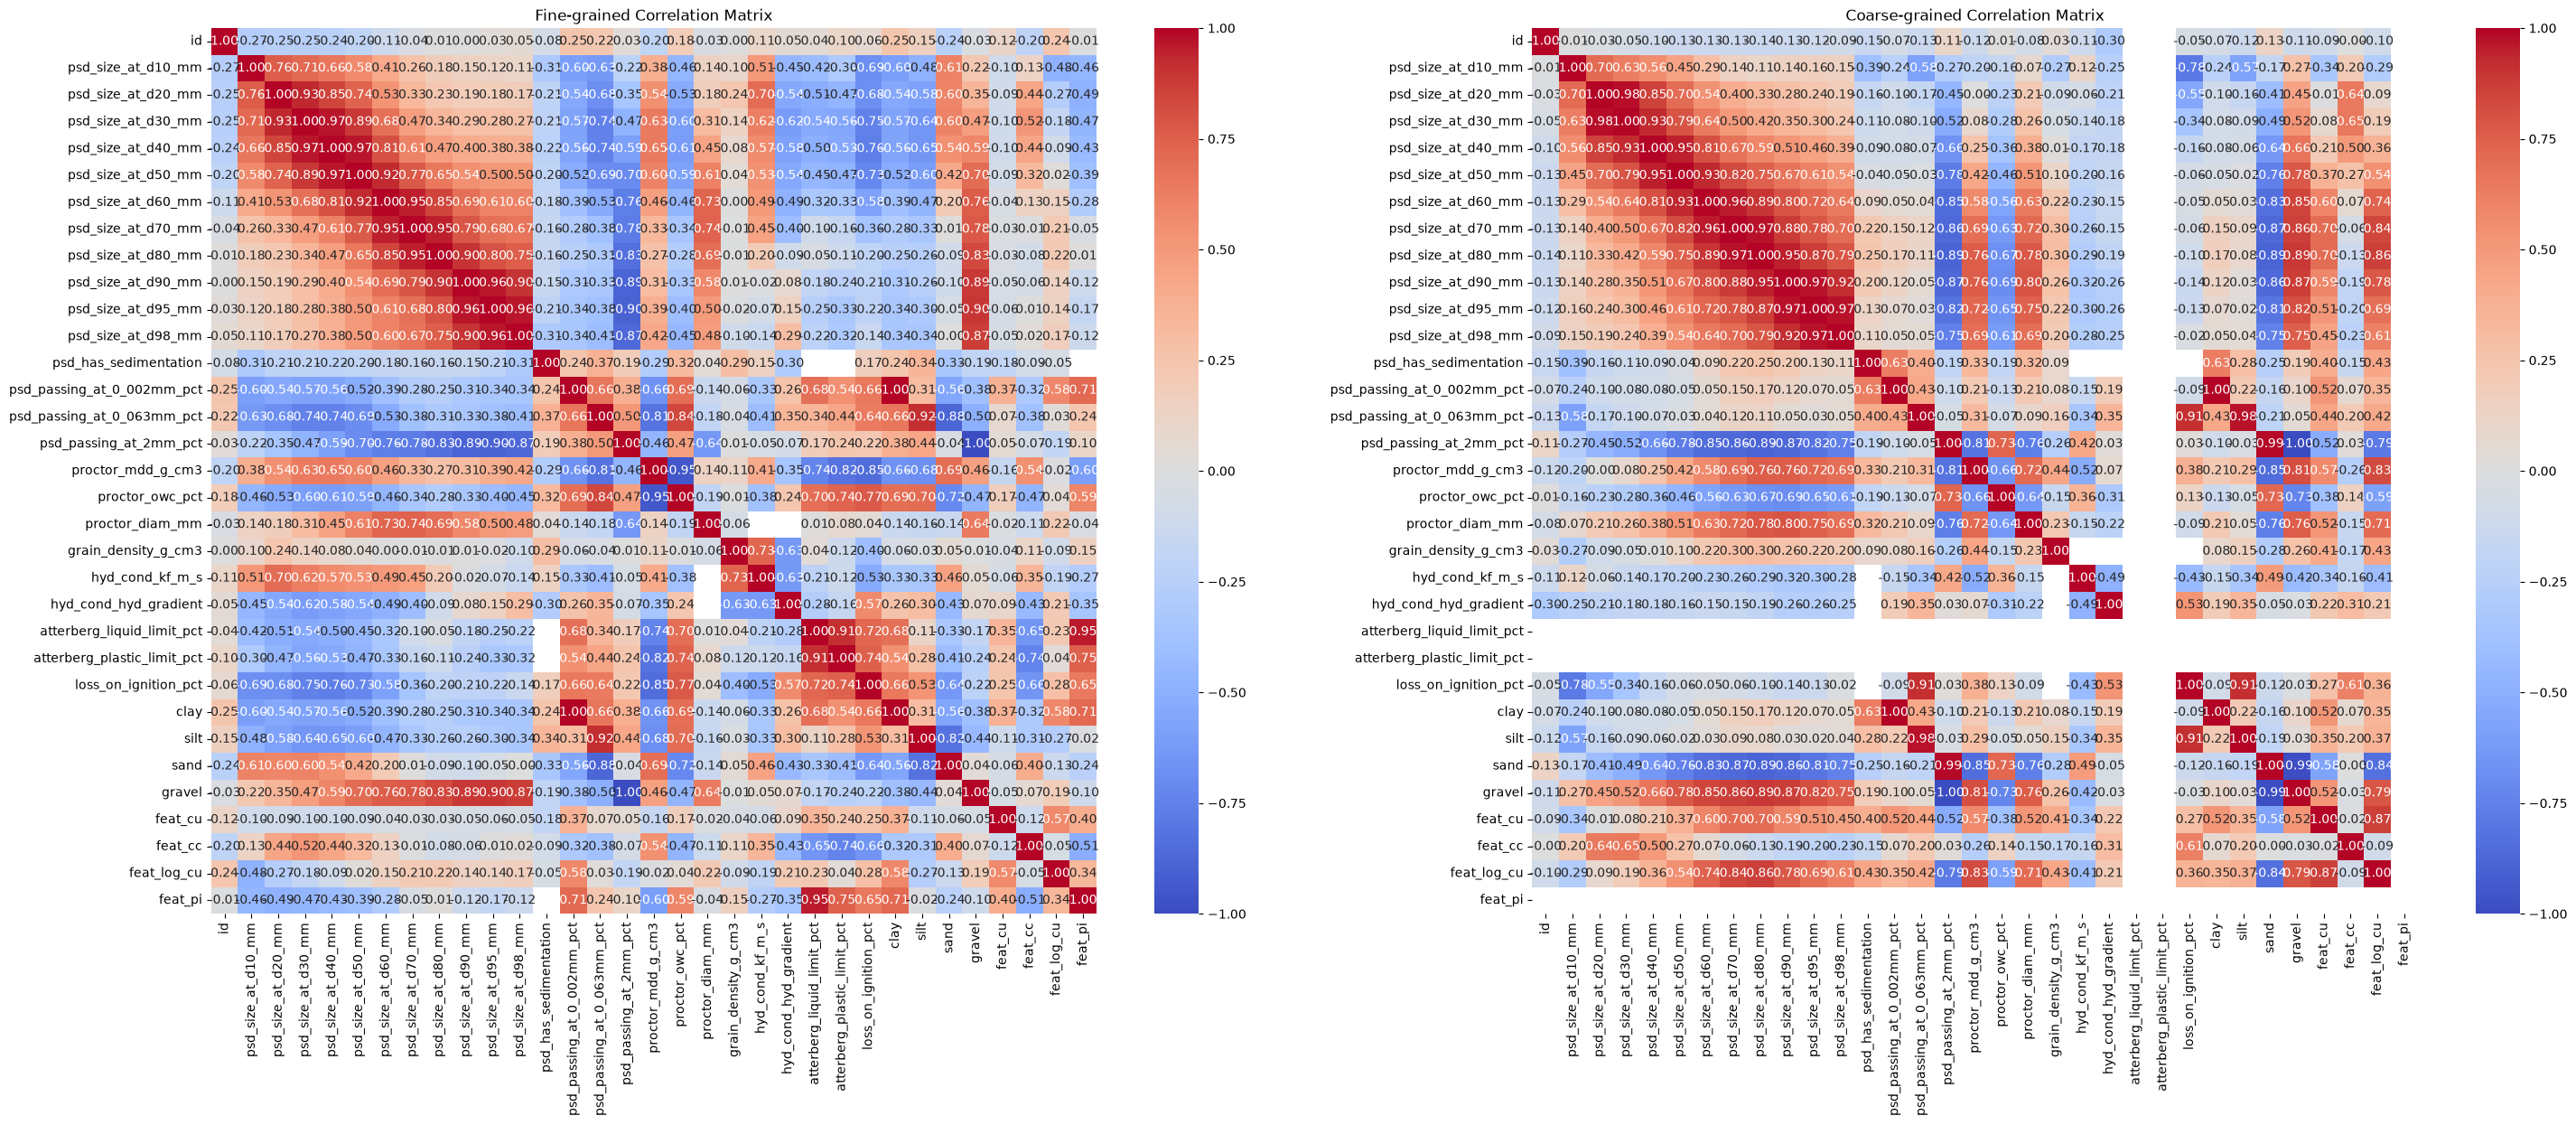

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(30, 12))

corr_heatmap(dff, ax=axes[0])
axes[0].set_title("Fine-grained Correlation Matrix")

corr_heatmap(dfc, ax=axes[1])
axes[1].set_title("Coarse-grained Correlation Matrix")

plt.tight_layout()
plt.show()

In [73]:
for c in dff.columns:
    if dff[c].isna().any():
        print(c)
print()
for c in dfc.columns:
    if dfc[c].isna().any():
        print(c)

hyd_cond_kf_m_s
hyd_cond_hyd_gradient
atterberg_liquid_limit_pct
atterberg_plastic_limit_pct
loss_on_ignition_pct
feat_pi

hyd_cond_kf_m_s
hyd_cond_hyd_gradient
atterberg_liquid_limit_pct
atterberg_plastic_limit_pct
loss_on_ignition_pct
feat_pi


In [74]:
import numpy as np

feature_cols = params_av.tolist()
target_col = "proctor_mdd_g_cm3"

X_mdd = df_impute[
    feature_cols
].copy()

y_mdd = df_impute[
    target_col
].astype(float).copy()

valid_mask = (
    X_mdd.notna().all(axis=1)
    & y_mdd.notna()
    & np.isfinite(y_mdd)
)

X_mdd = (
    X_mdd.loc[valid_mask]
    .reset_index(drop=True)
)

y_mdd = (
    y_mdd.loc[valid_mask]
    .reset_index(drop=True)
)

soil_type_mdd = (
    df_impute.loc[
        valid_mask,
        "fine-grained",
    ]
    .astype(int)
    .reset_index(drop=True)
)

In [75]:
mdd_general_model = GlobalResidualRegressor(
    alpha=None,
    alpha_bounds=(0.0, 1.5),
    n_splits=5,
    random_state=42,
)

mdd_general_model.fit(
    X_mdd,
    y_mdd,
)

mdd_general_model.get_training_summary()

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 4 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 5 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 5 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 4 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 9 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 10 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incr

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 4 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 8 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

...

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 4 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Incre

{'alpha': 0.8879271969215207,
 'ridge_oof_metrics': {'r2': 0.7439445102478752,
  'mae': 0.05669972223212838,
  'rmse': 0.07081069411477077},
 'global_hybrid_oof_metrics': {'r2': 0.8092334603647778,
  'mae': 0.045313165031522176,
  'rmse': 0.06111993825414024}}

In [76]:
mdd_oof = (
    mdd_general_model.get_oof_results(
        y=y_mdd,
        index=X_mdd.index,
    )
)

display(mdd_oof.head())

,observed,ridge_oof_prediction,ridge_residual,residual_model_oof_prediction,global_oof_prediction,remaining_residual
0,2.068,2.087594,-0.019594,0.022859,2.107891,-0.039891
1,2.037,2.071255,-0.034255,-0.065090,2.013460,0.023540
2,2.051,2.108076,-0.057076,-0.007651,2.101282,-0.050282
3,1.648,1.691210,-0.043210,-0.049246,1.647484,0.000516
4,1.820,1.920279,-0.100279,-0.007230,1.913860,-0.093860


In [77]:
residual = mdd_oof[
    "remaining_residual"
]

In [78]:
residual_analysis = X_mdd.copy()

residual_analysis["fine-grained"] = (
    soil_type_mdd
)

residual_analysis["remaining_residual"] = (
    residual.to_numpy()
)

In [79]:
residual_summary = (
    residual_analysis
    .groupby("fine-grained")[
        "remaining_residual"
    ]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        mean_absolute=lambda values:
            np.mean(np.abs(values)),
    )
)

display(residual_summary)

,count,mean,median,std,mean_absolute
fine-grained,,,,,
0,112,0.001925,-0.001568,0.049416,0.036792
1,89,-0.002825,0.000606,0.073753,0.056037


In [80]:
fine_mask = (
    soil_type_mdd.eq(1)
)

coarse_mask = (
    soil_type_mdd.eq(0)
)

fine_corr = (
    X_mdd.loc[fine_mask]
    .corrwith(
        residual.loc[fine_mask]
    )
    .sort_values(
        key=np.abs,
        ascending=False,
    )
)

coarse_corr = (
    X_mdd.loc[coarse_mask]
    .corrwith(
        residual.loc[coarse_mask]
    )
    .sort_values(
        key=np.abs,
        ascending=False,
    )
)

residual_correlations = pd.DataFrame(
    {
        "fine_residual_corr": fine_corr,
        "coarse_residual_corr": coarse_corr,
    }
)

residual_correlations[
    "correlation_difference"
] = (
    residual_correlations[
        "fine_residual_corr"
    ]
    - residual_correlations[
        "coarse_residual_corr"
    ]
).abs()

residual_correlations = (
    residual_correlations.sort_values(
        "correlation_difference",
        ascending=False,
    )
)

display(residual_correlations)

/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/junkyunglee/Codes/Co-op/proctor-prediction-challenge/.venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,fine_residual_corr,coarse_residual_corr,correlation_difference
sand,0.191555,-0.133734,0.325289
feat_cu,-0.366101,-0.043102,0.323000
gravel,-0.155524,0.127405,0.282928
psd_passing_at_2mm_pct,0.155524,-0.127405,0.282928
proctor_diam_mm,-0.175288,0.091685,0.266973
psd_size_at_d80_mm,-0.173864,0.064897,0.238761
psd_size_at_d90_mm,-0.166662,0.067612,0.234274
psd_size_at_d70_mm,-0.164248,0.065081,0.229329
psd_size_at_d95_mm,-0.141144,0.053339,0.194483
psd_size_at_d60_mm,-0.133524,0.038995,0.172519


In [180]:
dff

,id,psd_size_at_d10_mm,psd_size_at_d20_mm,psd_size_at_d30_mm,psd_size_at_d40_mm,psd_size_at_d50_mm,psd_size_at_d60_mm,psd_size_at_d70_mm,psd_size_at_d80_mm,psd_size_at_d90_mm,...,atterberg_plastic_limit_pct,loss_on_ignition_pct,clay,silt,sand,gravel,feat_cu,feat_cc,feat_log_cu,feat_pi
1,1,0.014579,0.062060,0.119258,0.221877,0.423550,1.022249,2.978369,6.081199,10.622063,...,NaN,1.3,4.27,15.96,45.26,34.51,70.117909,0.954313,4.264339,NaN
2,2,0.003243,0.022301,0.087024,0.156595,0.217595,0.323793,0.512853,1.546115,10.921905,...,13.75,NaN,8.84,18.35,54.21,18.60,99.843663,7.212132,4.613571,12.70
3,3,0.000355,0.000859,0.002080,0.004772,0.009031,0.015228,0.025404,0.041920,0.151357,...,22.44,4.3,29.56,54.76,15.29,0.39,42.895775,0.800305,3.781818,25.19
4,4,0.000360,0.004868,0.010546,0.015848,0.021282,0.026753,0.033510,0.042328,0.067946,...,NaN,1.7,15.09,74.46,9.73,0.72,74.313889,11.547834,4.321665,NaN
5,5,0.019744,0.142683,0.285699,0.353478,0.437337,0.544121,0.683417,0.858374,1.209994,...,NaN,0.7,0.00,15.72,82.98,1.30,27.558803,7.597782,3.351965,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190,190,0.000324,0.000991,0.002984,0.008524,0.022478,0.095630,0.295871,0.543019,1.510473,...,29.54,4.0,26.28,31.18,34.16,8.38,295.154321,0.287381,5.690881,30.99
191,191,0.002881,0.011201,0.025252,0.044632,0.076896,0.127275,0.168699,0.223605,0.333750,...,18.18,NaN,7.83,38.33,53.70,0.14,44.177369,1.739022,3.810596,9.76
193,193,0.002596,0.013750,0.072833,0.190724,0.312550,0.463404,0.691903,1.074778,2.969485,...,NaN,NaN,8.45,20.68,58.19,12.68,178.506934,4.409526,5.190214,NaN
199,199,0.000390,0.001069,0.002937,0.007530,0.014572,0.031049,0.105558,0.312777,0.629716,...,NaN,NaN,26.20,39.77,30.43,3.60,79.612821,0.712354,4.389658,NaN
